# Traballo 

En base ás outras columnas predecir os valores crash_risk_level. Análise de regresión con sklearn e rede neuronal con tensorflow, empregamos seaborn para representación de datos

O traballo pretende predecir puntuacións de crash_risk_level for caffeine mediante un dataframe de condicións biolóxicas e sociais como de habitos de conduta. Non entendamos isto como un diagnóstico senón como un por centaxe de factor de risco.

Teños dúas opcións: ou determino a variable str <<crash_risk_level>> ou determio numéricamente <<crash_severity_score>>. Creo que facer a primeira é o correcto, a segunda é unha variable continua e debería separala en rangos o que daría moi erro nas fronteiras.

Mirar o que di o Kaggle sobre o database para escribir isto

## 1. Depuración de datos

## Pendente!!!
Liña 10 da cela 5, mellorable a presentación. Fará falta labels_2? Falta facer a introducción

Se podo talvez sería interesante utilizar os modelo de SVR (regresións) para predecir os scores quitando tamén a columna de risk. 

In [287]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import sys
import os
sys.path.append(os.getcwd())

In [288]:
# https://www.kaggle.com/datasets/samartalwar/caffeine-crash-and-jitters-energy-drinks-and-anxiety
df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv')
df.head()

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


In [289]:
df.info() # sinala automaticamente onde hai valores nulos e o tipo de columna

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   str    
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   str    
 3   cyp1a2_metabolizer_type   8000 non-null   str    
 4   caffeine_tolerance        8000 non-null   str    
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   str    
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   float64
 14  acute_anxiety_score

In [290]:
# agora vemos datos máis pormenorizadamente, e.g., para <<crash_risk_level>> porque pretenderemos predicila, podemos ver calquera das columnas que nos devolve df.info()
print(f"{'crash_risk_level'}: \n{df['crash_risk_level'].describe()}")
df.crash_risk_level.unique()

crash_risk_level: 
count                          8000
unique                            4
top       Moderate Crash & Lethargy
freq                           2426
Name: crash_risk_level, dtype: object


<StringArray>
[      'Mild Afternoon Fatigue', 'Sustained / Negligible Crash',
    'Moderate Crash & Lethargy',   'Severe Crash & Tachycardia']
Length: 4, dtype: str

Vemos que no noso dataset non temos columnas que conteñan celas baleiras. As columnas <<user_id>>, << gender>>, <<cyp1a2_metabolizer_type>>, <<caffeine_tolerance>>, <<primary_caffeine_source>> e <<crash_risk_level>> son strings. Estes datos teremos que depuralos, no caso de <<user_id>> non nos aportará nada de información e <<crash_risk_level>> non será necesario tocala en principio porque aplicaremos as nosas técnicas tal cal sobre a variable str.

In [291]:
for i in range(1,len(df.columns)):
    if df[df.columns[i]].dtypes == 'str':
        print(f'Na columna <<{df.columns[i]}>> pódense tomar os seguintes valores {df[df.columns[i]].unique()}')

s = 0 # isto serve para contar cantos suxeitos satisfan certo valor
for i in range(len(df)):
    if df['crash_risk_level'].iloc[i] == 'Severe Crash & Tachycardia':
        s += 1
print(f'En gender hai {s} Non-Binary') # podo poñer isto máis xeral 2377 , 1036, 2426, 2161

Na columna <<gender>> pódense tomar os seguintes valores <StringArray>
['Female', 'Male', 'Non-Binary']
Length: 3, dtype: str
Na columna <<cyp1a2_metabolizer_type>> pódense tomar os seguintes valores <StringArray>
['Fast', 'Normal', 'Slow']
Length: 3, dtype: str
Na columna <<caffeine_tolerance>> pódense tomar os seguintes valores <StringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str
Na columna <<primary_caffeine_source>> pódense tomar os seguintes valores <StringArray>
[         'Brewed Drip Coffee',   'Energy Drink (Sugar-Free)',
   'Energy Drink (Full Sugar)',      'Pre-Workout Supplement',
 'Espresso / Specialty Drinks',          'Matcha / Green Tea']
Length: 6, dtype: str
Na columna <<crash_risk_level>> pódense tomar os seguintes valores <StringArray>
[      'Mild Afternoon Fatigue', 'Sustained / Negligible Crash',
    'Moderate Crash & Lethargy',   'Severe Crash & Tachycardia']
Length: 4, dtype: str
En gender hai 2161 Non-Binary


Segundo os valores que vemos, as variables <<cyp1a2_metabolizer_type>> e <<caffeine_tolerance>> pódense poñer perfectamente como datos numéricos cun diccionario. Para os casos << gender>>, <<primary_caffeine_source>> e <<crash_risk_level>> o mellor é traballar con variables dummies. Decatémonos que a primeira columna non nos aporta ningunha información, é un código de identificación do suxeito avaliado. O mellor é eliminalo.

In [292]:
gender_dummies = pd.get_dummies(df['gender'], prefix='gender', dtype=int)
primary_caffeine_source_dummies = pd.get_dummies(df['primary_caffeine_source'], prefix='primary_caffeine_source', dtype=int)
crash_risk_level_dummies = pd.get_dummies(df['crash_risk_level'], prefix='crash_risk_level', dtype=int)
# En principio non será necesario para os calculos utilizar crash_risk_level_dummies, si será interesante para poñer a matriz de correlación

df['cyp1a2_metabolizer_type'] = df['cyp1a2_metabolizer_type'].map({'Fast':2, 'Normal':1, 'Slow':0})
df['cyp1a2_metabolizer_type'] = df['cyp1a2_metabolizer_type'].fillna(0) # por se acaso aparecen NaN pois que sexan lexibles numericamente

df['caffeine_tolerance'] = df['caffeine_tolerance'].map({'High':2, 'Moderate':1, 'Low':0})
df['caffeine_tolerance'] = df['caffeine_tolerance'].fillna(0)

df = df.rename(columns = {'cyp1a2_metabolizer_type': 'cyp1a2_metabolizer_speed_type'})

# como na sección seguinte aínda nos vai interesar utilizar o noso dataframe df con algunhas variables str utilizamos unha copia para cando
# sexa necesario empregar os dummies que será nos puntos 3 e 4. A columna <<user_id>> só nos entorpece; eliminámola directamente.
Df = df.copy()
Df = pd.concat([Df.drop(columns=['user_id','gender','primary_caffeine_source']),
                                gender_dummies, primary_caffeine_source_dummies],
                                axis=1)

Df.head()


,age,cyp1a2_metabolizer_speed_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,...,crash_risk_level,gender_Female,gender_Male,gender_Non-Binary,primary_caffeine_source_Brewed Drip Coffee,primary_caffeine_source_Energy Drink (Full Sugar),primary_caffeine_source_Energy Drink (Sugar-Free),primary_caffeine_source_Espresso / Specialty Drinks,primary_caffeine_source_Matcha / Green Tea,primary_caffeine_source_Pre-Workout Supplement
0,27,2,2,2.4,7.0,2.29,138,8.7,36,2.0,...,Mild Afternoon Fatigue,1,0,0,1,0,0,0,0,0
1,57,2,0,9.1,7.1,2.41,164,0.0,3,2.4,...,Sustained / Negligible Crash,1,0,0,0,0,1,0,0,0
2,39,1,0,2.9,5.1,2.07,179,36.9,10,3.8,...,Moderate Crash & Lethargy,0,1,0,0,1,0,0,0,0
3,34,2,1,3.8,5.0,2.34,408,1.6,3,6.8,...,Severe Crash & Tachycardia,1,0,0,0,0,0,0,0,1
4,22,0,2,2.0,6.3,1.92,170,50.2,11,2.0,...,Severe Crash & Tachycardia,1,0,0,0,1,0,0,0,0


Por último comprobamos que non haxa dexeneración nos nosos datos (filas duplicadas).

In [293]:
if df.duplicated().sum() > 0:
    print(f'Hai {df.duplicated().sum()} filas duplicadas (dexeneración de datos) no DataFrame. Logo temos que depurar estos datos duplicados, e.g. eliminándoos')
else:
    print('Non hai filas duplicadas. Nada que facer.')

Non hai filas duplicadas. Nada que facer.


## 2. Representacións estatísticas

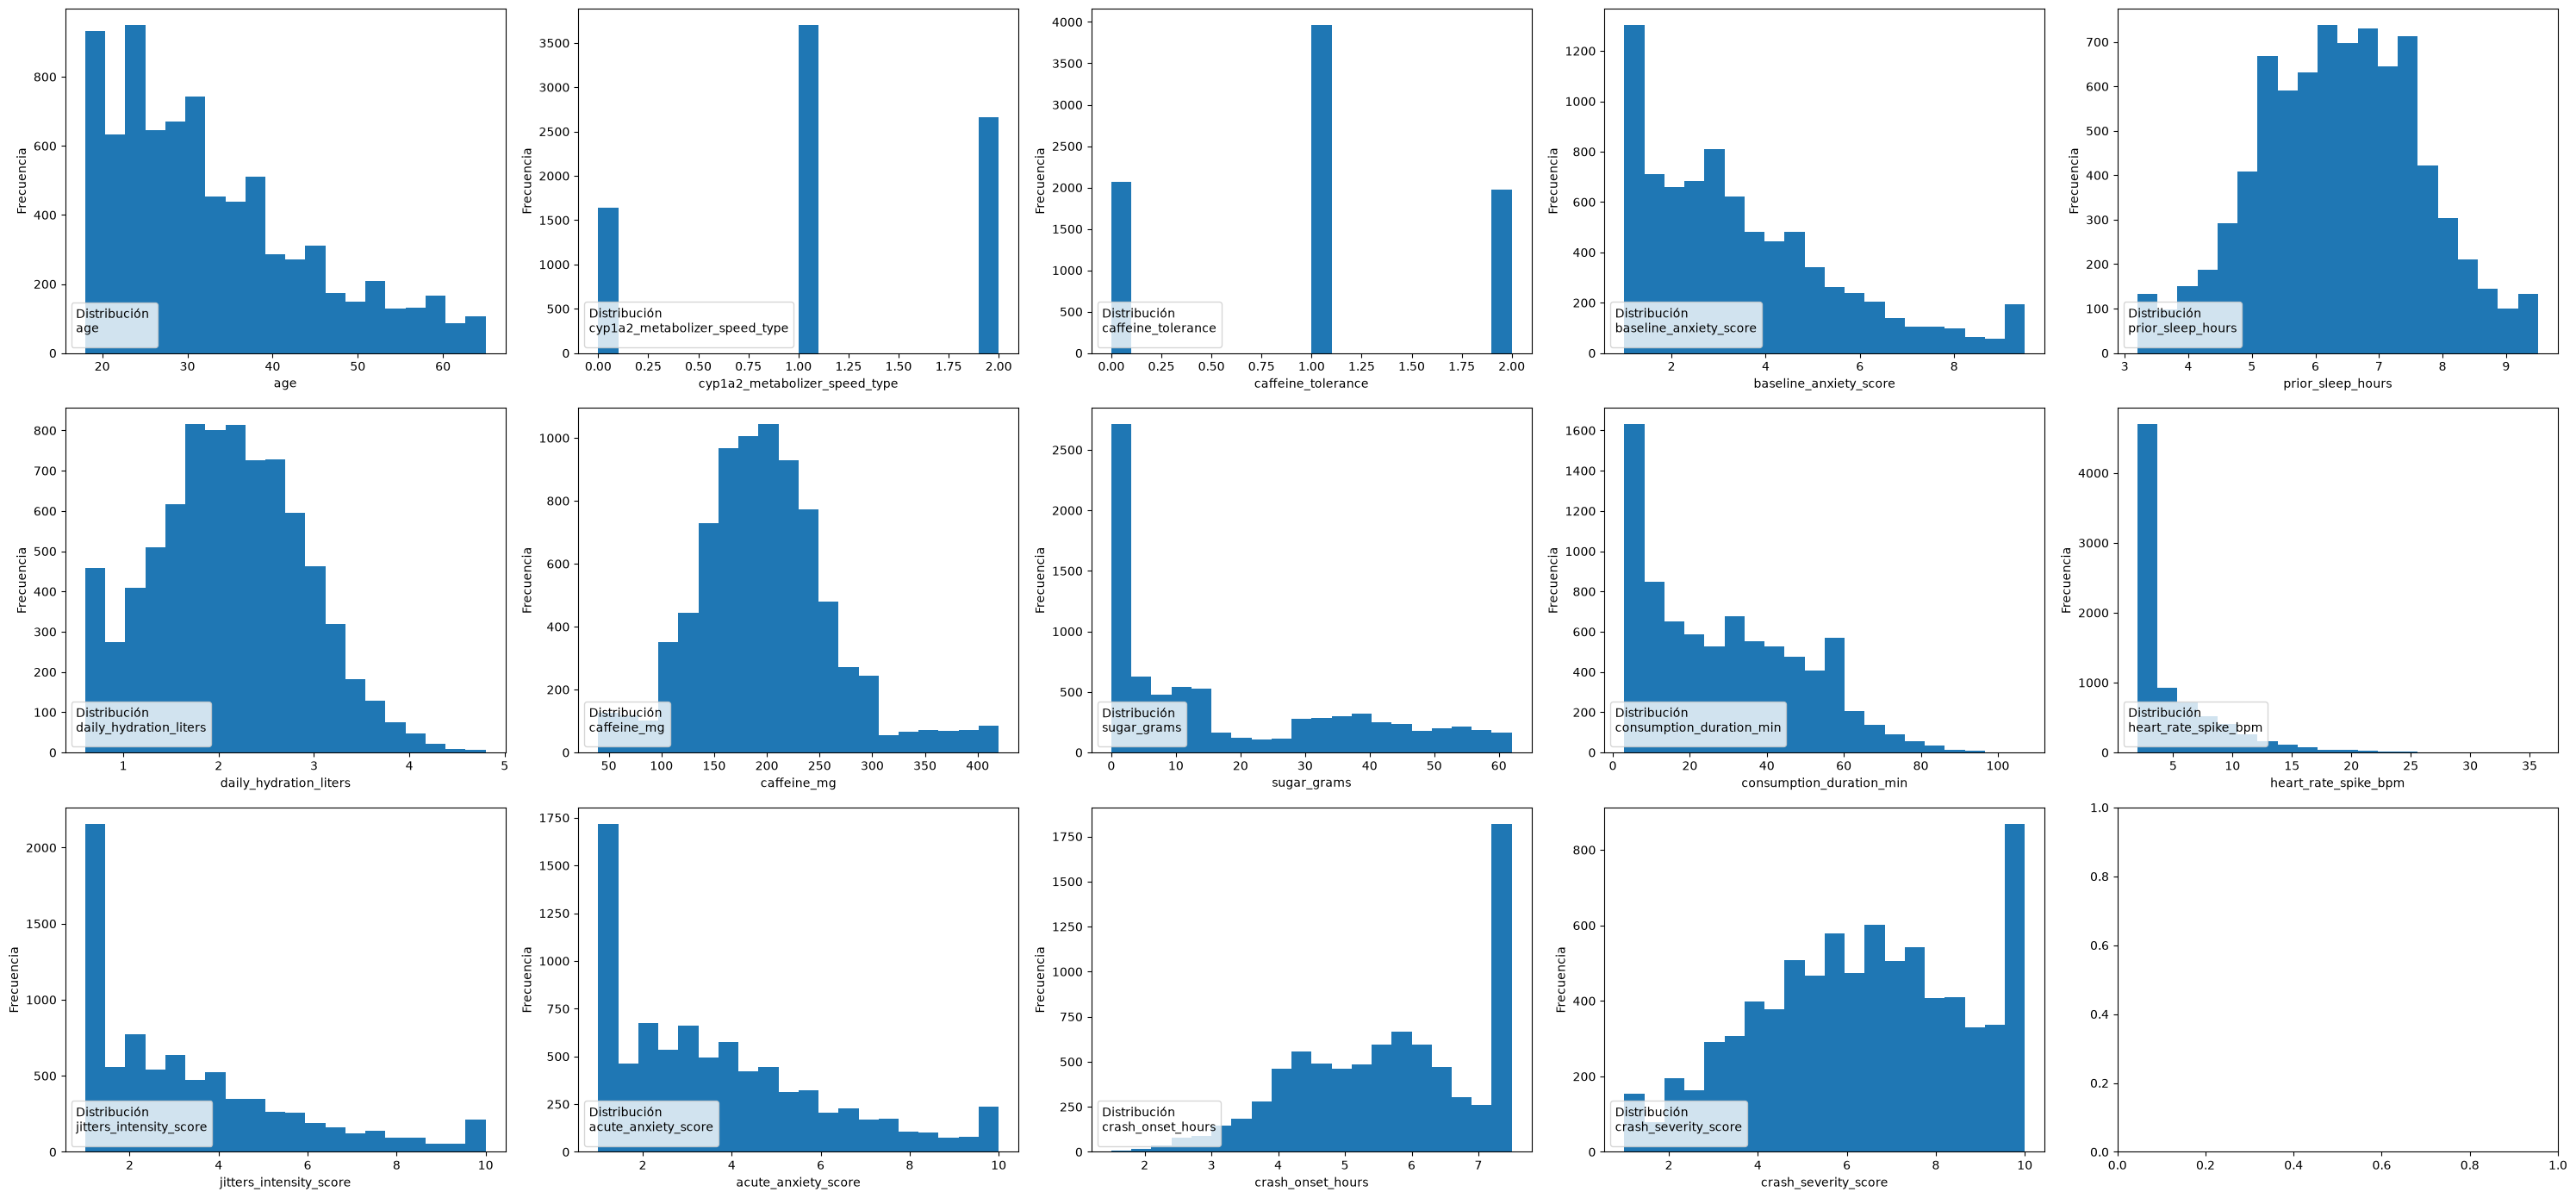

In [294]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
fig, axs = plt.subplots(3,5, figsize=(30, 14))

num_vert = 0; num_hor = 0
for cols in numeric_cols: 
    
    axs[num_vert,num_hor].hist(df[cols], bins=20)
    axs[num_vert,num_hor].legend( title=f'Distribución \n{cols}', loc='lower left')
    axs[num_vert,num_hor].axes.get_xaxis().set_visible(True)
    axs[num_vert,num_hor].axes.get_yaxis().set_visible(True)
    axs[num_vert,num_hor].set_xlabel(f'{cols}')
    axs[num_vert,num_hor].set_ylabel('Frecuencia')
    
    num_hor += 1
    if num_vert == 0 and num_hor == 5:
            num_vert = 1
            num_hor = 0

    elif num_vert == 1 and num_hor == 5:
            num_vert = 2
            num_hor = 0    
        
plt.tight_layout()
fig.show()

Así a vista podemos ver que as nosas variables distribúense en xeral nalgunha clase de distribución exponencial ou gaussiana. Na gran maioría o dato da moda resulta atípico, aínda que realmente podemos pensar que isto é realmente un punto que nos indica que as variables están fortemente ligadas, e.g., que moita xente teña un consumo de azucre próximo a 0 gramos pode xustificar que a maioría dos accidentes ocorran máis de 6 horas despois da inxesta se é que o azucre funciona como un catalizador; ou, máis obvio, que a gran maioría de persoas non se autoperciban síntomas de tremores pode coincidir con non detectar unha $\Delta$ BPM tamén na gran maioría. Nos casos gaussianos atopamos unha distribución interesante sobre hábitos de vida como a cantidade de auga que se bebe como as de horas que durmen. Tamén nos decatamos que a gran maioría de pacentes foron precisamente xente xove (menores de 34 anos) aos que se asocia un maior número de consumo de bebidas enerxéticas fronte a formas tradicionais de consumo de cafeína (café ou té).

In [295]:
# Pode ser interesante revisar a media e a moda dalgunhas distribucións, por exemplo:
distrib = ('prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg' ,'crash_onset_hours', 'crash_severity_score')
for cat in distrib:
    print(f'En {cat} a media é {df[cat].mean():.2f} e a moda é {df[cat].mode().tolist()[0]}')

En prior_sleep_hours a media é 6.38 e a moda é 6.7
En daily_hydration_liters a media é 2.11 e a moda é 0.6
En caffeine_mg a media é 198.04 e a moda é 197
En crash_onset_hours a media é 5.65 e a moda é 7.5
En crash_severity_score a media é 6.29 e a moda é 10.0


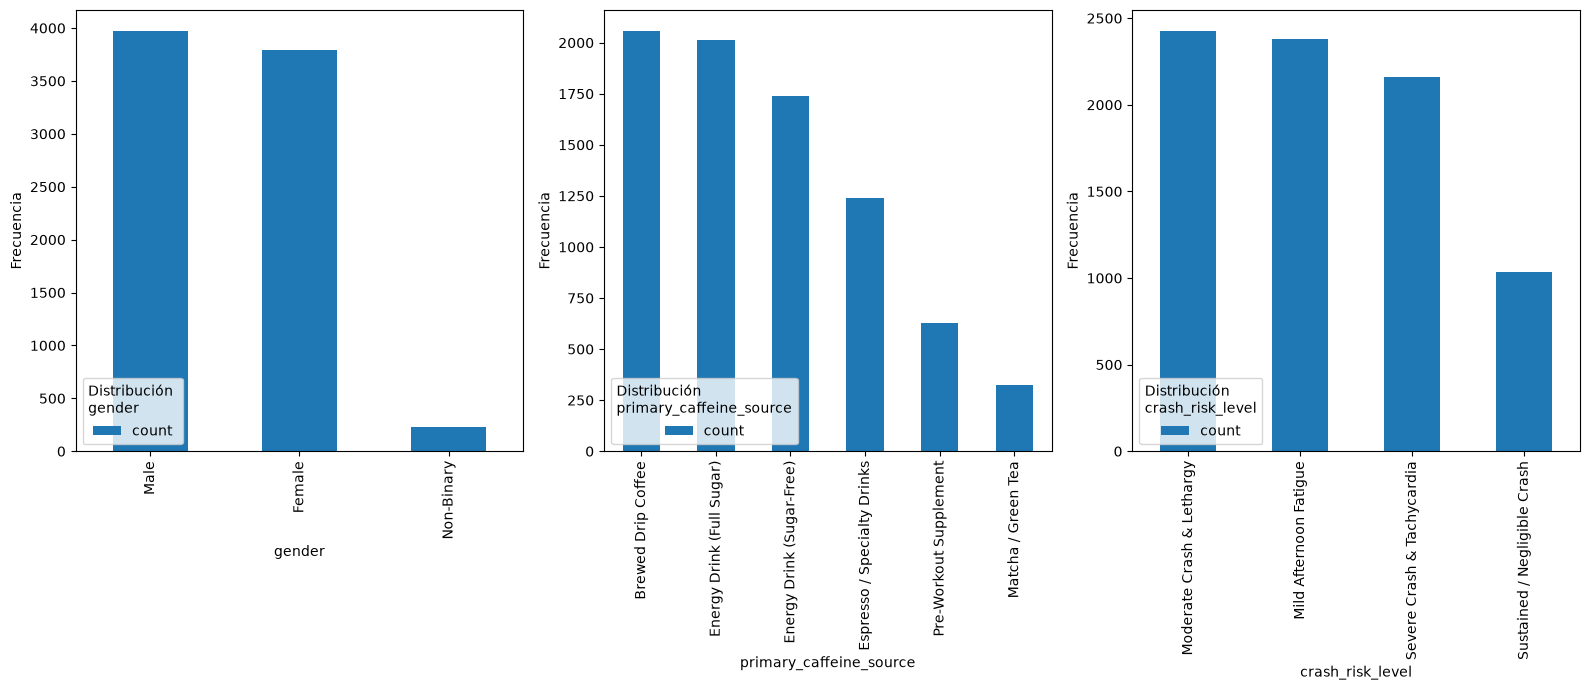

In [296]:
categorical_cols = df.select_dtypes(include=['object']).columns

fig, axs = plt.subplots(1,3, figsize=(16, 7))

num_hor = 0
for col in categorical_cols[1:]:
    df[col].value_counts().plot(kind='bar', ax=axs[num_hor])
    axs[num_hor].legend(title=f'Distribución \n{col}', loc='lower left')
    axs[num_hor].set_xlabel(col)
    axs[num_hor].set_ylabel('Frecuencia')
    num_hor += 1
        
plt.tight_layout()
fig.show()

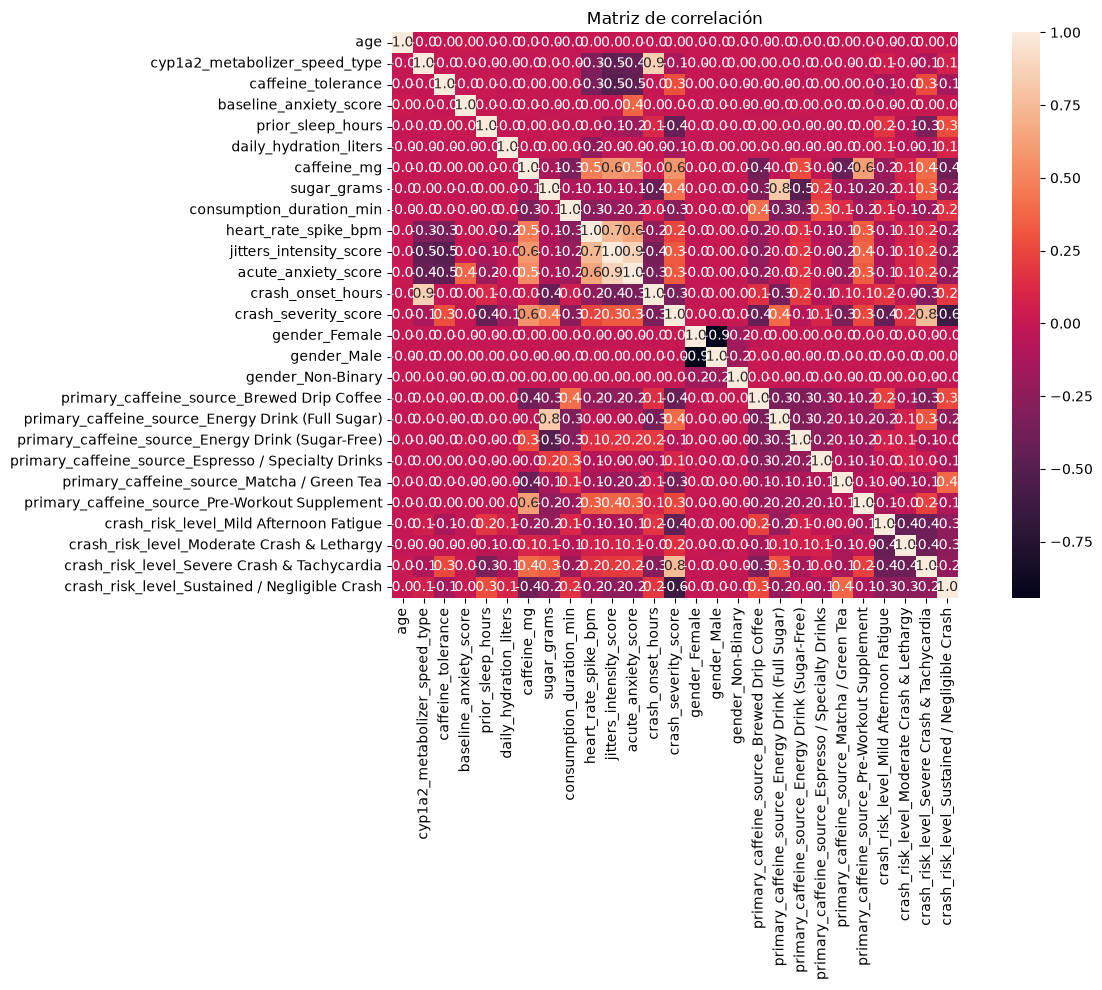

In [297]:
# Aquí empregamos o DataFrame Df con todas as columnas str traducidas ou empregando os dummies respectivos; isto é necesario
# para facer correlacións numéricas.

# Mapa de calor da matriz de correlación do noso dataframe completamente numérico
plt.figure(figsize=(14, 10))
sns.heatmap(pd.concat([Df.drop(columns=['crash_risk_level']),crash_risk_level_dummies],axis=1).select_dtypes(include='number').corr(), 
            annot=True, fmt='.1f', square=True#, cmap='coolwarm'
            )
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

Vemos que na diagonal aparecen 3 cadradados pequenos de correlación negativa moi significativa, isto derívase de que son as submatrices das variables dummies que son autoexcluíntes. Obviamente non pode haber un suxeito home e muller á vez (obviando identificacións de xénero fluído) ou que alguén teña dúas gravidades distintas no crash. 

Vemos a continuación un pouco máis en detalle algunha variable significativa nas predicións.

In [298]:
# Imos facer categorías para <<caffeine_mg>> e <<sugar_grams>> para comparalas con <<crash_risk_level>> 
# As categorías escolloas así un pouco a ollo, a cafeína semella unha gaussiana así facemos division 25 50 25
# e o azucre é exponencial ou incluso cadrada se obviamos o 0, escollemos unha equiseparación 33.33 33.33 33.33
# Tamén compararemos as <<primary_caffeine_source>> con <<crash_risk_level>> 

p25, p75 = df["caffeine_mg"].quantile([0.25, 0.75])
p33, p66 = df["sugar_grams"].quantile([0.3333, 0.6666])

def categorize_caffeine(score): # en cuartiles (aínda que o primer 25 chega aos 157mg que me parece pila)
    # corrixome unha enerxética zero do Día (a que me estou tomando agora mesmo) pequena (250ml) ten 31mg/100ml --> 77,5 mg
    # logo, como a maioría de enerxéticas son de 500 ml, cunha cantidade semellante de cafeína ten uns 150 mg 
    if score <= p25: # <25%
        return 'Low'
    elif score <= p75: # 25 - 75%
            return 'Medium'
    else:
        return 'High' # >75%

def categorize_sugar(score): # en terciles 
    if score <= p33: # <33.33%
        return 'Low'
    elif score <= p66:
            return 'Medium' # 33.33-66.66%
    else:
        return 'High' # >66.66%

caffeine_level = df['caffeine_mg'].apply(categorize_caffeine)
sugar_level = df['sugar_grams'].apply(categorize_sugar)

corr_cafe_sugar_source = pd.concat([caffeine_level, sugar_level, df['primary_caffeine_source'],df['crash_risk_level']], axis=1)
corr_cafe_sugar_source.head()

,caffeine_mg,sugar_grams,primary_caffeine_source,crash_risk_level
0,Low,Medium,Brewed Drip Coffee,Mild Afternoon Fatigue
1,Medium,Low,Energy Drink (Sugar-Free),Sustained / Negligible Crash
2,Medium,High,Energy Drink (Full Sugar),Moderate Crash & Lethargy
3,High,Low,Pre-Workout Supplement,Severe Crash & Tachycardia
4,Medium,High,Energy Drink (Full Sugar),Severe Crash & Tachycardia


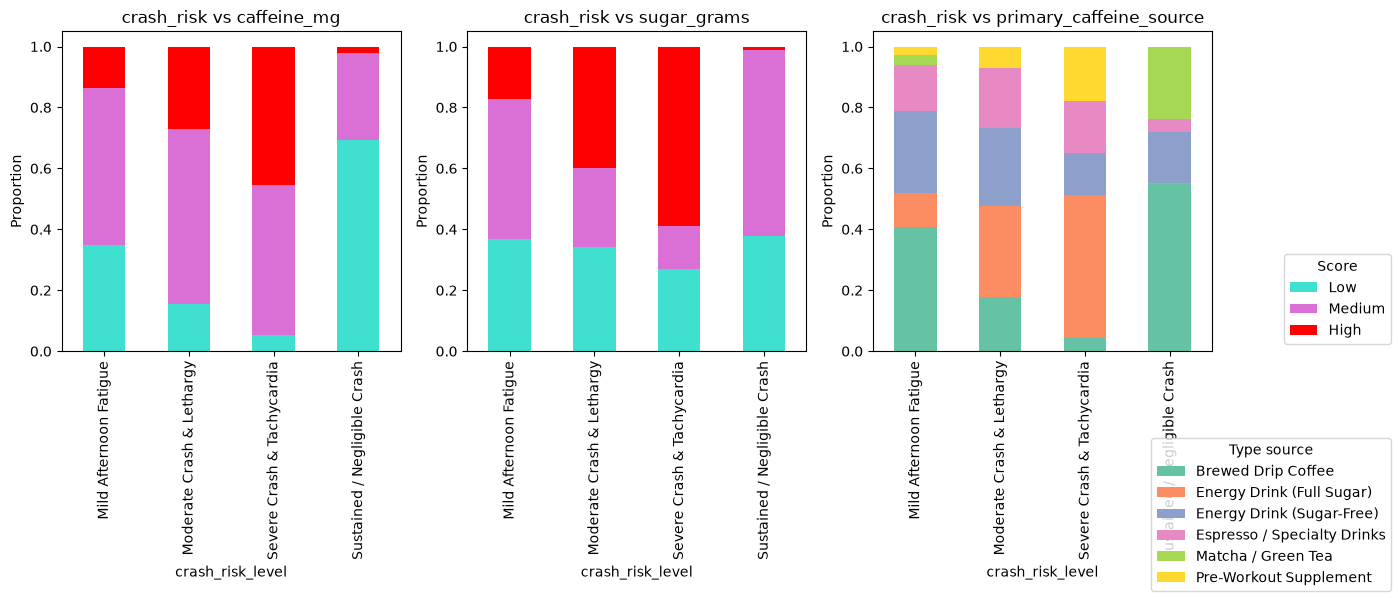

In [299]:
Scores = ('caffeine_mg', 'sugar_grams')
Rangos = ('Low', 'Medium', 'High')
cores = ['turquoise', 'orchid', 'r']

fig, axs = plt.subplots(1, 3, figsize=(14, 6))

for i, score in enumerate(Scores):
    score_distribution = (
        corr_cafe_sugar_source
        .groupby('crash_risk_level')[score]
        .value_counts(normalize=True)
        .unstack()
        .reindex(columns=Rangos, fill_value=0)
        )

    score_distribution.plot(
        kind='bar',
        stacked=True,
        ax=axs[i],
        color=cores,
        legend=False
        )
    
    axs[i].set_title(f'crash_risk vs {score}')
    # axs[i].set_xlabel('Crash risk level') # non creo que falla falta, é bsatante intuitiva a gráfica
    axs[i].set_ylabel('Proportion')

# facemos un plot especial para poder ver stackeadas dúas variables str por proporción
crash_vs_source = pd.crosstab(corr_cafe_sugar_source['crash_risk_level'], corr_cafe_sugar_source['primary_caffeine_source'], normalize='index')
cores = sns.color_palette('Set2', n_colors=crash_vs_source.shape[1])
crash_vs_source.plot(kind='bar', stacked=True, ax=axs[2], color=cores, legend=False)
axs[2].set_title(f'crash_risk vs primary_caffeine_source')
axs[2].set_ylabel('Proportion')

handles, label_1 = axs[0].get_legend_handles_labels()
handles1, label_2 = axs[2].get_legend_handles_labels()
fig.legend(handles, label_1, title='Score', loc='center right')
fig.legend(handles1, label_2, title='Type source', loc='lower right')

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

Agora, previo a proceder ás dúas análises de predicción da variable <<crash_risk_level>> debemos separar as nosas mostras de datos en datos de entrenamento e de testeo. Será necesario que utilizemos o dataframe onde substituímos as columnas str polos dummies respectivos (Df) que serán sempre os datos de interese no resto do noso estudo.

In [300]:
y1 = Df.crash_risk_level

labels_1 = ['Mild Afternoon Fatigue', # son os elementos de y1, será necesario telo definido. De momento non sei se fará falta un labels_2
    'Moderate Crash & Lethargy',
    'Severe Crash & Tachycardia',
    'Sustained / Negligible Crash'] 

In [301]:
x1 = Df.drop(columns=['crash_risk_level'])

In [302]:
split = round(x1.shape[0]*0.80) # todas as X son do mesmo tamaño, non distinguimos, 80% de entreno e 20% de testeo
x1_train, x1_test = x1[:split], x1[split:]
y1_train, y1_test = y1[:split], y1[split:]

## 3. Análise con sklearn (regresión loxística)

Primeiro normalizo as variables

In [303]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x1_train_scaled = scaler.fit_transform(x1_train)
x1_test_scaled = scaler.transform(x1_test)

#### 3.0.1 Modelo Linear

Toca empezar a crear modelos, o primeiro será linear e empregarei un cálculo a man da optimización do hiperparámetro alpha, este é bastante pequeno así que para reducir o costo computacional xa o teño posto cerquiña do valor real que calcula (estiven 12 minutos esperando cunha partición máis fina nun intervalo máis grande XoX)

In [304]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score

alpha = np.arange(1e-15, 0.000001, 0.00000005)
val_scores = np.zeros(len(alpha))

for i, a in enumerate(alpha):
    model_cross = SGDClassifier(
            loss='hinge', penalty='l2', alpha=a, random_state=100
        )
    score = cross_val_score(model_cross, x1_train_scaled, y1_train, cv=5)
    val_scores[i] = score.mean()

ind = np.argmax(val_scores)
print('O mellor valor de alpha é', alpha[ind])


O mellor valor de alpha é 6.500000009999999e-07


In [305]:
model_linear = SGDClassifier(loss='hinge', penalty='l2', alpha=alpha[ind])
model_trained_1 = model_linear.fit(x1_train_scaled, y1_train)

y1_hat_train_1 = model_trained_1.predict(x1_train_scaled)
y1_hat_test_1 = model_trained_1.predict(x1_test_scaled)

In [306]:
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print(f'A exactitude de predición do modelo linear no conxunto de adestramento é {accuracy_score(y1_train, y1_hat_train_1):.4f}')
print(f'A exactitude de predición do modelo linear no conxunto de teste é {accuracy_score(y1_test, y1_hat_test_1):.4f}')

print(
    classification_report(
        y1_test,
        y1_hat_test_1,
        target_names=labels_1
    )
)

A exactitude de predición do modelo linear no conxunto de adestramento é 0.7552
A exactitude de predición do modelo linear no conxunto de teste é 0.7569
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.60      0.43      0.50       443
   Moderate Crash & Lethargy       0.60      0.75      0.67       509
  Severe Crash & Tachycardia       1.00      0.98      0.99       435
Sustained / Negligible Crash       0.97      0.99      0.98       213

                    accuracy                           0.76      1600
                   macro avg       0.79      0.79      0.78      1600
                weighted avg       0.76      0.76      0.75      1600



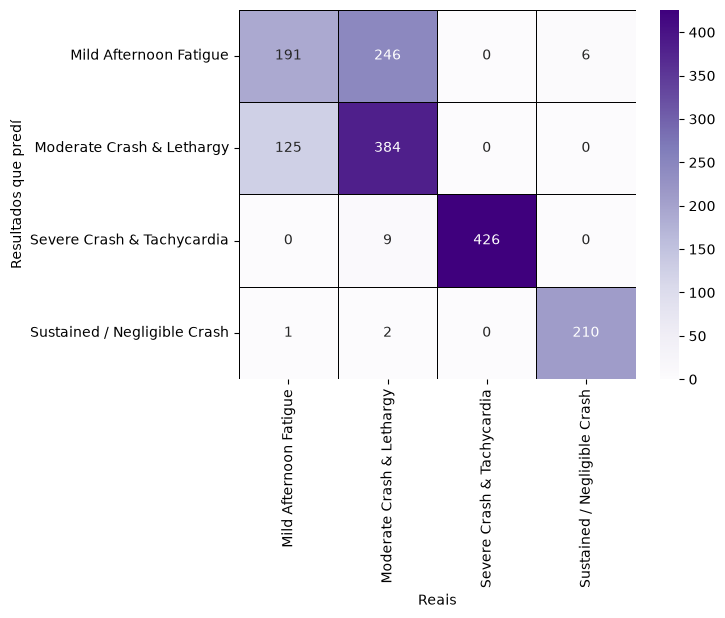

In [307]:
from sklearn.metrics import confusion_matrix

cm_1 = confusion_matrix(y1_test, y1_hat_test_1, labels=labels_1)

sns.heatmap(cm_1, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Resultados que predí') #Ponemos título al eje y
plt.xlabel('Reais') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor

#### 3.0.2 Modelo RBF
Modelo Radial Basis Function, é un modelo gaussiano con fronteiras non-lineares, espérase que se axuste moito mellor que unha recta ao considerar precisamente asociacións non lineares

In [308]:
from sklearn.svm import SVC

model_rbf = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

model_trained_2 = model_rbf.fit(x1_train_scaled, y1_train)

y1_hat_train_2 = model_trained_2.predict(x1_train_scaled)
y1_hat_test_2 = model_trained_2.predict(x1_test_scaled)

In [309]:
print(f'A exactitude de predición do modelo rbf no conxunto de adestramento é {accuracy_score(y1_train, y1_hat_train_2):.4f}')
print(f'A exactitude de predición do modelo rbf no conxunto de teste é {accuracy_score(y1_test, y1_hat_test_2):.4f}')

print(
    classification_report(
        y1_test,
        y1_hat_test_2,
        target_names=labels_1
    )
)

A exactitude de predición do modelo rbf no conxunto de adestramento é 0.9608
A exactitude de predición do modelo rbf no conxunto de teste é 0.9244
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.90      0.94      0.92       443
   Moderate Crash & Lethargy       0.91      0.94      0.92       509
  Severe Crash & Tachycardia       0.96      0.92      0.94       435
Sustained / Negligible Crash       0.94      0.86      0.90       213

                    accuracy                           0.92      1600
                   macro avg       0.93      0.92      0.92      1600
                weighted avg       0.93      0.92      0.92      1600



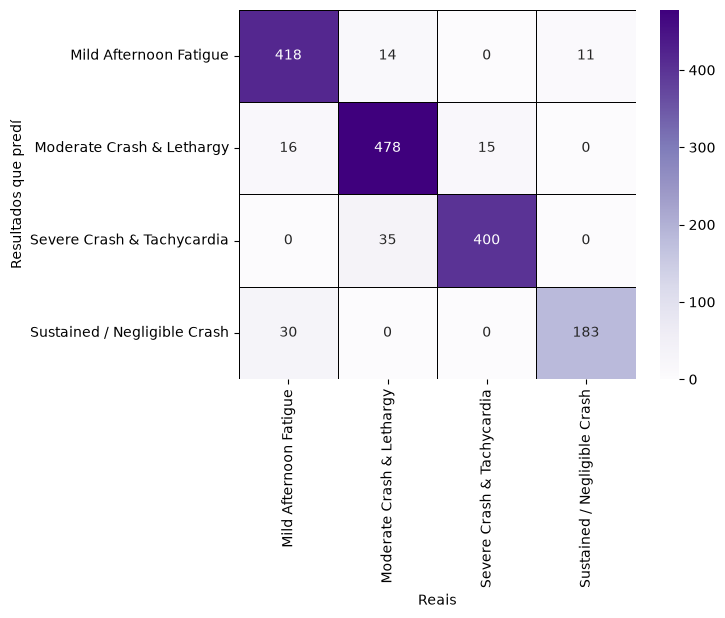

In [310]:
cm_2 = confusion_matrix(y1_test, y1_hat_test_2, labels=labels_1)

sns.heatmap(cm_2, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

### 3.1 Análise sen sesgo

In [311]:
# o nome da sección é por poñer algo, non sei que poñer.
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    x1_train_scaled,
    y1_train,
    random_state=100
)

for col, val in sorted(zip(x1.columns, mi),
                       key=lambda x1: x1[1],
                       reverse=True):
    print(col, round(val,4))

crash_severity_score 1.3402
caffeine_mg 0.217
sugar_grams 0.1812
primary_caffeine_source_Brewed Drip Coffee 0.0941
prior_sleep_hours 0.0891
primary_caffeine_source_Energy Drink (Full Sugar) 0.0816
crash_onset_hours 0.0753
jitters_intensity_score 0.0701
primary_caffeine_source_Matcha / Green Tea 0.0641
acute_anxiety_score 0.0559
caffeine_tolerance 0.0411
heart_rate_spike_bpm 0.0381
consumption_duration_min 0.0333
primary_caffeine_source_Pre-Workout Supplement 0.0331
primary_caffeine_source_Espresso / Specialty Drinks 0.0271
cyp1a2_metabolizer_speed_type 0.0227
primary_caffeine_source_Energy Drink (Sugar-Free) 0.0196
daily_hydration_liters 0.0088
baseline_anxiety_score 0.0071
gender_Male 0.0049
gender_Non-Binary 0.0002
age 0.0
gender_Female 0.0


aquí vemos que a columna <<crash_severity_score>> ten un 1.34 de correlación o que quere dicir que lle está "chivando" moita información ao modelo, o seu sería ver como se comporta sen empregar esta columna, logo, repetindo considerando ese caso, i.e., facendo un drop no noso dataframe definindo de novo as x's e as y's

In [312]:
y2 = Df.crash_risk_level # satisfaise que y1 == y2; pero por poder facelos distinguibles
x2 = Df.drop(columns=['crash_risk_level','crash_severity_score'])

split = round(x2.shape[0]*0.80) # todas as X son do mesmo tamaño, non distinguimos, 80% de entreno e 20% de testeo
x2_train, x2_test = x2[:split], x2[split:]
y2_train, y2_test = y2[:split], y2[split:]

x2_train_scaled = scaler.fit_transform(x2_train)
x2_test_scaled = scaler.transform(x2_test)

#### 3.1.1 Estimación, training e resultados do Modelo Linear/Loxístico linear

Agora imos predecir adecuadamente os parámetros de todos os nosos modelos. En vez de empregar un cálculo a man como se fixo antes para o caso linear empregamos unha función de sklearn que se chama `GridSearchCV`. Primeiro vemos o caso da linear a ver que tal se axusta e de ser necesario correximos o `loss`, que antes usamos `loss = hinge` que é o caso linear, e o `penalty` que os escollimos anteriormente sen xustificación. É de esperar que o axuste loxístico (`loss = log_loss`) sexa mellor que linear, así que comparamos o valor do `best_score_` para determinalo; representaremos só os resultados do mellor entre os dous.

In [313]:
from sklearn.model_selection import GridSearchCV

param_linear = {
    'loss': ['hinge'],
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [1e-5, 1e-4, 1e-3, 1e-2, 5e-3]
}

grid_linear = GridSearchCV(
    estimator = SGDClassifier(random_state=100),
    param_grid = param_linear,
    cv = 10, # é o número de cross validations que fai o algoritmo; se poño moitas posibilidades no param_grid é necesario aumentalo, pero aumenta moitisimo o custe computacional
    scoring = 'f1_macro', # neste caso a columna <<crash_risk_level>> ten as proporcións de datos 2377, 1036, 2426, 2161 --> 29.7, 12.9, 30.3, 27.0 %
    # non é unha diferenza moi significativa polo que tanto empregar 'accuracy' como 'f1_macro' son boas opcións; escollo a segunda para balancear mellor
    n_jobs = -1 # emprega todos os núcleos da cpu: moito máis rápido pero pode saturar outros programas abertos
)

grid_linear.fit(x2_train_scaled, y2_train)
best_model_linear = grid_linear.best_estimator_ # escollemos automaticamente o modelo mellor estimado (o de mellores parámetros)

param_log = {
    'loss': ['log_loss'], # usar 'modified_huber' dá resultados moi lixeiramente mellores, pero non é tipo loxístico
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [1e-5, 1e-4, 1e-3, 1e-2, 5e-3]
}

grid_log = GridSearchCV(
    estimator = SGDClassifier(random_state=100),
    param_grid = param_log,
    cv = 10, 
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_linear.fit(x2_train_scaled, y2_train)
grid_log.fit(x2_train_scaled, y2_train)
best_model_log = grid_log.best_estimator_

# o mellor modelo escóllese precisamente con aquel que entre todas as combinacións de parámetros dados posibles teña o scoring (f1-macro) máximo, 
# cada scoring é media de todas as validacións cruzadas para esos parámetros
print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_linear.best_score_:.4f}')
print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_log.best_score_:.4f}')
if grid_log.best_score_ > grid_linear.best_score_:
    print('A regresión loxística axústase mellor que a linear.')
else:
    print('A regresión linear axústase mellor que a loxística.')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.6697
O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.7467
A regresión loxística axústase mellor que a linear.


In [314]:
y2_hat_train_1 = best_model_log.predict(x2_train_scaled)
y2_hat_test_1 = best_model_log.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo Loxístico son {grid_log.best_params_}')
print(f'A exactitude de predición do modelo Loxístico no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_1):.4f}')
print(f'A exactitude de predición do modelo Loxístico no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_1):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_hat_test_1,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo Loxístico son {'alpha': 0.005, 'loss': 'log_loss', 'penalty': 'l1'}
A exactitude de predición do modelo Loxístico no conxunto de adestramento é 0.7439
A exactitude de predición do modelo Loxístico no conxunto de teste é 0.7331

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.65      0.73      0.69       443
   Moderate Crash & Lethargy       0.71      0.62      0.66       509
  Severe Crash & Tachycardia       0.82      0.89      0.85       435
Sustained / Negligible Crash       0.80      0.69      0.74       213

                    accuracy                           0.73      1600
                   macro avg       0.74      0.73      0.74      1600
                weighted avg       0.73      0.73      0.73      1600



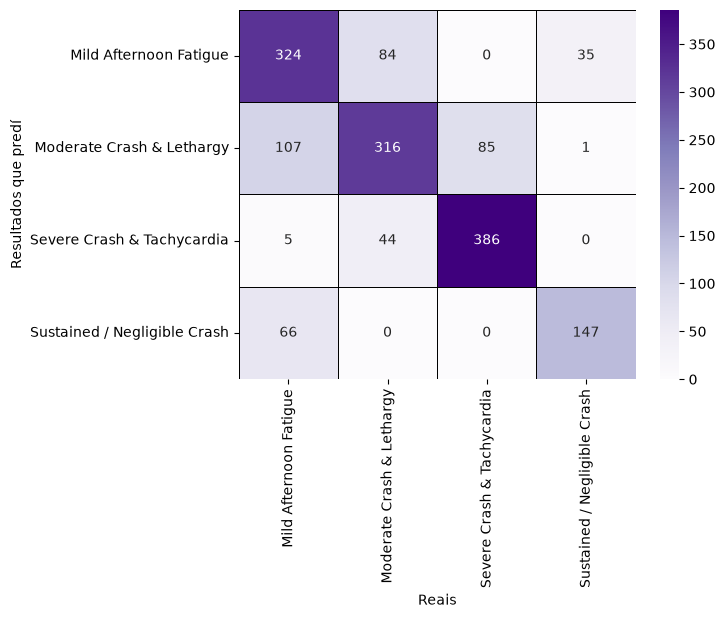

In [315]:
cm_3 = confusion_matrix(y2_test, y2_hat_test_1, labels=labels_1)

sns.heatmap(cm_3, cmap='Purples', annot=True, fmt='d', linewidths=0.6, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

#### 3.1.2 Estimación, training e resultados do Modelo RBF

In [316]:
param_rbf = {
    'C': [1, 10, 20, 50],
    'gamma': [0.005, 0.01, 0.05, 0.1]
}

grid_rbf = GridSearchCV(
    estimator = SVC(kernel='rbf'),
    param_grid = param_rbf,
    cv = 5,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_rbf.fit(x2_train_scaled, y2_train)
best_model_rbf = grid_rbf.best_estimator_

print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_rbf.best_score_:.4f}')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.8039


In [317]:
y2_hat_train_2 = best_model_rbf.predict(x2_train_scaled)
y2_hat_test_2 = best_model_rbf.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo RBF son {grid_rbf.best_params_}')
print(f'A exactitude de predición do modelo RBF no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_2):.4f}')
print(f'A exactitude de predición do modelo RBF no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_2):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_hat_test_2,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo RBF son {'C': 20, 'gamma': 0.01}
A exactitude de predición do modelo RBF no conxunto de adestramento é 0.8384
A exactitude de predición do modelo RBF no conxunto de teste é 0.7875

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.78      0.75       443
   Moderate Crash & Lethargy       0.75      0.77      0.76       509
  Severe Crash & Tachycardia       0.89      0.84      0.87       435
Sustained / Negligible Crash       0.82      0.74      0.78       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600



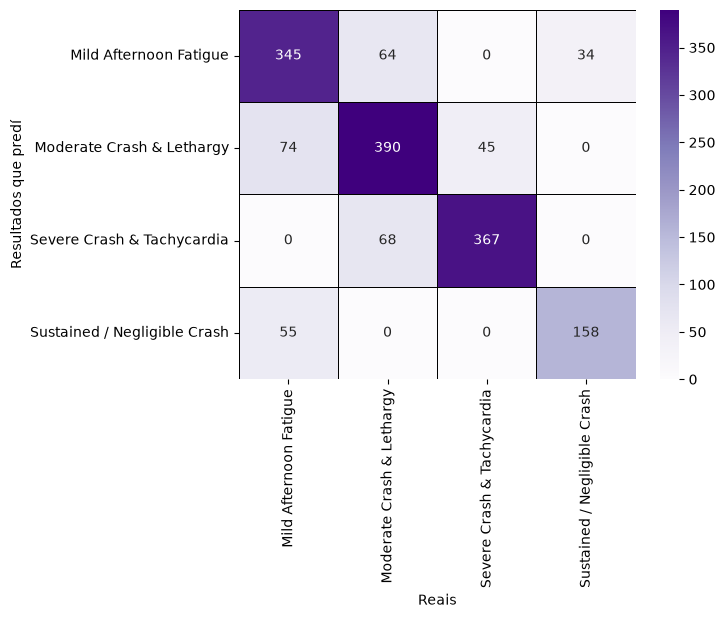

In [318]:
cm_4 = confusion_matrix(y2_test, y2_hat_test_2, labels=labels_1)

sns.heatmap(cm_4, cmap='Purples', annot=True, fmt='d', linewidths=0.6, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

#### 3.1.3 Estimación, training e resultados do Modelo RandomForest

Imos probar ademais tamén con outros modelos, neste caso tipo árbore. Por unha banda empregamos un sistema de árbores independentes `RandomForestClassifier()` e pola outra un sistema de árbores secuenciais `HistGradientBoostingClassifier`

**Caption.**     O tempo de compilado dos modelos tipo árbore é bastante extenso, teño un procesador bastante potente e aínda así tárdame ao redor 1 minuto cada un.

In [319]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

param_forest = {
    'n_estimators': [400, 500, 600],
    'max_depth': [None, 10, 20, 25],
    'min_samples_leaf': [1, 2, 3]
}

grid_forest = GridSearchCV(
    RandomForestClassifier(random_state=100),
    param_grid = param_forest,
    cv = 5,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_forest.fit(x2_train_scaled, y2_train)
best_model_forest = grid_forest.best_estimator_

print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_forest.best_score_:.4f}')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.7522


In [320]:
y2_hat_train_3 = best_model_forest.predict(x2_train_scaled)
y2_hat_test_3 = best_model_forest.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo RandomForestClassifier son {grid_forest.best_params_}')
print(f'A exactitude de predición do modelo RandomForestClassifier no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_3):.4f}')
print(f'A exactitude de predición do modelo RandomForestClassifier no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_3):.4f}\n')

print(
    classification_report(
        y1_test,
        y1_hat_test_2,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo RandomForestClassifier son {'max_depth': 25, 'min_samples_leaf': 1, 'n_estimators': 500}
A exactitude de predición do modelo RandomForestClassifier no conxunto de adestramento é 1.0000
A exactitude de predición do modelo RandomForestClassifier no conxunto de teste é 0.7600

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.90      0.94      0.92       443
   Moderate Crash & Lethargy       0.91      0.94      0.92       509
  Severe Crash & Tachycardia       0.96      0.92      0.94       435
Sustained / Negligible Crash       0.94      0.86      0.90       213

                    accuracy                           0.92      1600
                   macro avg       0.93      0.92      0.92      1600
                weighted avg       0.93      0.92      0.92      1600



As nosas árbores teñen un n bastante alto de estimadores (500) o que lle permite practicamente "memorizar" os resultados do entrenamento, de aí que a precisión á hora de predecilos sexa exacta e sen erros 

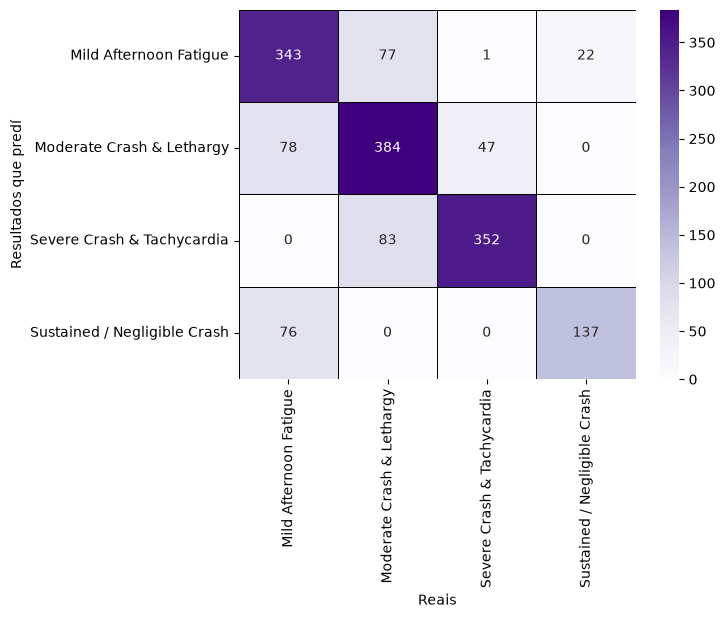

In [321]:
cm_5 = confusion_matrix(y2_test, y2_hat_test_3, labels=labels_1)

sns.heatmap(cm_5, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

#### 3.1.4 Estimación, training e resultados do Modelo HistGradientBoosting

In [322]:
param_boost = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 10],
    'max_iter': [100, 200, 500]
}

grid_boost = GridSearchCV(
    HistGradientBoostingClassifier(random_state=100),
    param_grid = param_boost,
    cv = 5,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_boost.fit(x2_train_scaled, y2_train)
best_model_boost = grid_boost.best_estimator_

print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_boost.best_score_:.4f}')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.7866


In [323]:
y2_hat_train_4 = best_model_boost.predict(x2_train_scaled)
y2_hat_test_4 = best_model_boost.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo HistGradientBoosting son {grid_boost.best_params_}')
print(f'A exactitude de predición do modelo HistGradientBoosting no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_4):.4f}')
print(f'A exactitude de predición do modelo HistGradientBoosting no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_4):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_hat_test_4,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo HistGradientBoosting son {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 500}
A exactitude de predición do modelo HistGradientBoosting no conxunto de adestramento é 0.9136
A exactitude de predición do modelo HistGradientBoosting no conxunto de teste é 0.7750

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.72      0.76      0.74       443
   Moderate Crash & Lethargy       0.74      0.75      0.75       509
  Severe Crash & Tachycardia       0.87      0.84      0.85       435
Sustained / Negligible Crash       0.80      0.72      0.76       213

                    accuracy                           0.78      1600
                   macro avg       0.78      0.77      0.77      1600
                weighted avg       0.78      0.78      0.78      1600



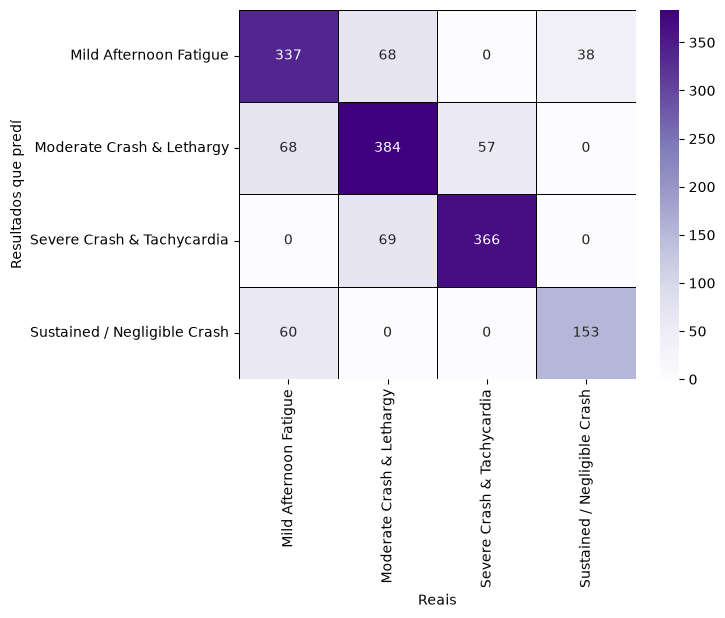

In [324]:
cm_6 = confusion_matrix(y2_test, y2_hat_test_4, labels=labels_1)

sns.heatmap(cm_6, cmap='Purples', annot=True, fmt='d', linewidths=0.6, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

### 3.2 Conclusións

Primeiro fixemos os cálculos incluíndo a columna de score e obtivemos

In [325]:
print(f'Para o modelo linear obtivemos unha exactitude do {accuracy_score(y1_test, y1_hat_test_1)*100:.2f}% e para o RBF unha do {accuracy_score(y1_test, y1_hat_test_2)*100:.2f}%')
if accuracy_score(y1_test, y1_hat_test_1) > accuracy_score(y1_test, y1_hat_test_2):
    print('A pesar das limitacións dun modelo linear predice mellor que un gaussiano')
else:
    print('O modelo gaussiano predí mellor, como se esperaba, que o modelo linear')

Para o modelo linear obtivemos unha exactitude do 75.69% e para o RBF unha do 92.44%
O modelo gaussiano predí mellor, como se esperaba, que o modelo linear


Ambos modelos predicen moi ben o conxunto de teste. O linear, como é de esperar, é bastante limitado, pola contra o RBF cun score do 92% é algo extraordinario que se pode xustificar, como se dixo, pola alta correlación entre as columnas <<crash_risk_level>> e <<crash_severity_score>>.

En consecuencia volvemos a realizar os cálculos eliminando a columna <<crash_severity_score>> e para asegurar uns bos resultados optimizamos por validación cruzada os parámetros dos modelos. Os nosos resultados de predición sobre o conxunto de teste son

In [326]:
print(f'Para o modelo loxístico obtivemos unha exactitude do {accuracy_score(y2_test, y2_hat_test_1)*100:.2f}%, para o RBF unha do {accuracy_score(y2_test, y2_hat_test_2)*100:.2f}%, para o modelo RandomForest \nunha do {accuracy_score(y2_test, y2_hat_test_3)*100:.2f}% e para o modelo HistGradientBoosting é de {accuracy_score(y2_test, y2_hat_test_4)*100:.2f}%')

resultados = {
    'Loxístico': accuracy_score(y2_test, y2_hat_test_1),
    'RBF': accuracy_score(y2_test, y2_hat_test_2),
    'RandomForest': accuracy_score(y2_test, y2_hat_test_3),
    'HistGradientBoosting': accuracy_score(y2_test, y2_hat_test_4)
}

print(f'Todos os modelos teñen unha capacidade de predición semellante, o {max(resultados, key=resultados.get)} é lixeiramente mellor, superando incluso aos modelos de árbore.')

Para o modelo loxístico obtivemos unha exactitude do 73.31%, para o RBF unha do 78.75%, para o modelo RandomForest 
unha do 76.00% e para o modelo HistGradientBoosting é de 77.50%
Todos os modelos teñen unha capacidade de predición semellante, o RBF é lixeiramente mellor, superando incluso aos modelos de árbore.


### 3.3 Análise de regresións (Score)

# 4. Análise con tensorflow (rede neuronal)

In [327]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y2_train_enc = le.fit_transform(y2_train)
y2_test_enc = le.transform(y2_test)

In [328]:
from keras import layers
from keras.models import Sequential
from keras.regularizers import L2

model = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model.summary()# vou probar a modificar a rede, meto o soft no medio

Model: "sequential_46"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_282 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_283 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_284 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_285 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_286 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_287 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,056 (23.66 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

Parece que en SGD() aplicar inercia é moi contraproducente nos meus datos, aplico un nesterov para unha capa de preprocesado e un ratio pequeno (0.001) e os loss son ~cte a unha distancia de 0.06 (necesitaria moitos epochs), se probo a quitar o nesterov e poño un ratio de 0.01 obteño ruído e cun de 0.001. 

Probo a cambiar o modelo e meto agora un l2 na saída. Con rate 0.001 funciona moi ben, os loss decaen conxuntos pero necesitaría moitos epochs ~100. Probo con 0.01 e se observa moi ben a curva, no final despéganse un pouco (0.05). O seu sería de momento incrementar os epochs con 0.001. Repito o anterior, lixo igual. Cambio SGD por Adam, de momento é lixo, incluso poñendo moitas iteracións e pasos pequenos hai moito ruído. Nadam para 0.0001 dá unh moi boa curva pero separadas unha constante 0.003 (igual que se poño 0.001 para SDG), con 0.001 e con 0.01 dá puro ruído. Por último AdamW para 0.0004/0.0001 moito ruído, 0.001/0.0002 ruído. Non sei moi ben como melloralo.

cambio validation_split a validation_data
Probo con 0.0001 en SDG a 100 epochs, modifico tamén o batch_size 10-->16: 0.805, 0.613 / 0.790, 0.631 --> 0.805, 0.612 / 0.788, 0.631
agora batch_size --> 8: inicial 0.807, 0.613 / 0.790, 0.632 --> 0.805, 0.613 / 0.790, 0.631 (un pelín ruidosa)
collo o mellor (batch_size = 16)

quito l2 da saída, compórtase ben. A 0.01 ten ruído no final poño batch 10--16, cristo

Isto non vale para nada. Vou volver a compilar todo

In [329]:
from keras.optimizers import SGD, Adam, Nadam, AdamW

model.compile(
    optimizer=SGD(learning_rate=0.001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0002),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=10, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

Epoch 1/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3664 - loss: 4.3265 - val_accuracy: 0.3950 - val_loss: 4.2484
Epoch 2/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4084 - loss: 4.1718 - val_accuracy: 0.4175 - val_loss: 4.1043
Epoch 3/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4494 - loss: 4.0308 - val_accuracy: 0.4638 - val_loss: 3.9724
Epoch 4/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4911 - loss: 3.9006 - val_accuracy: 0.4869 - val_loss: 3.8538
Epoch 5/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5166 - loss: 3.7752 - val_accuracy: 0.5125 - val_loss: 3.7333
Epoch 6/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5420 - loss: 3.6516 - val_accuracy: 0.5487 - val_loss: 3.6106
Epoch 7/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5830 - loss: 3.5277 - val_accuracy: 0.5931 - val_loss: 3.4939
Epoch 8/100
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6270 - loss: 3.4064 - val_accu

In [330]:
y2_neuron_train_class = np.argmax(model.predict(x2_train_scaled), axis=1)
y2_neuron_train_labels = le.inverse_transform(y2_neuron_train_class)
y2_neuron_test_class = np.argmax(model.predict(x2_test_scaled), axis=1)
y2_neuron_test_labels = le.inverse_transform(y2_neuron_test_class)

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y2_neuron_train_labels):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y2_neuron_test_labels):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_neuron_test_labels,
        target_names=labels_1
    )
)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8178
A exactitude de predición da rede neuronal no conxunto de teste é 0.7994

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.78      0.76       443
   Moderate Crash & Lethargy       0.77      0.77      0.77       509
  Severe Crash & Tachycardia       0.89      0.86      0.88       435
Sustained / Negligible Crash       0.80      0.77      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600



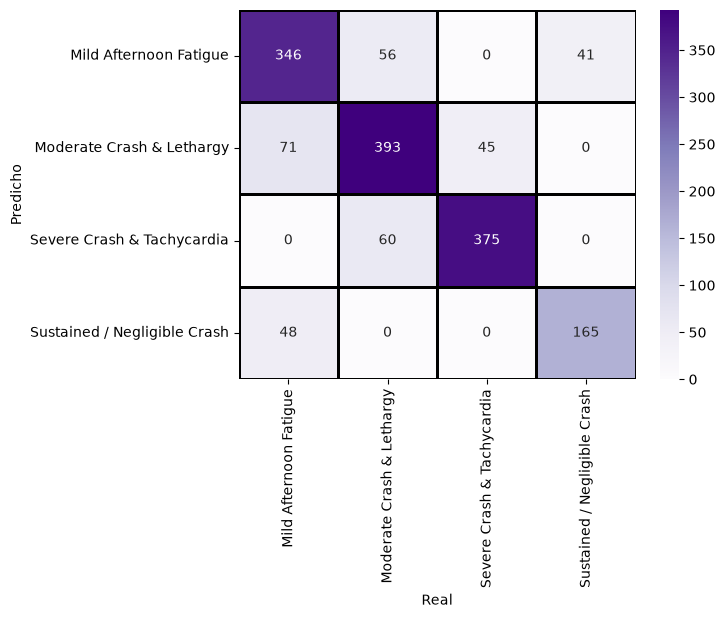

In [331]:
cm_rede = confusion_matrix(y2_test, y2_neuron_test_labels, labels=labels_1)

sns.heatmap(cm_rede, cmap='Purples', annot=True, fmt='d', linewidths=1, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Predicho')
plt.xlabel('Real')
plt.show()

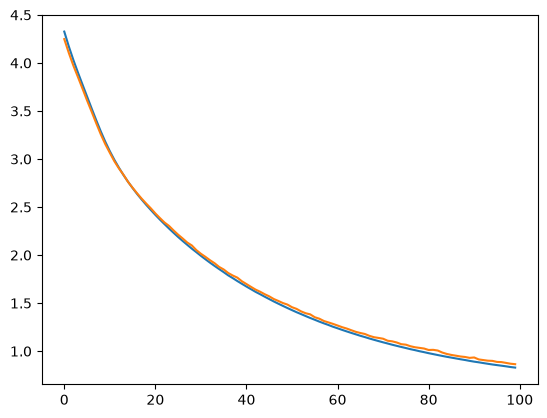

In [332]:
plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])

In [333]:
print(cerebro.history['accuracy'][-1])
print(cerebro.history['val_accuracy'][-1])
print(cerebro.history['loss'][-1])
print(cerebro.history['val_loss'][-1])

0.8173437714576721
0.7993749976158142
0.8291702270507812
0.8645341396331787


Vou deixar compilando isto toda a noite a ver que tal

1. soft de presaida
    1.1 SGD
    1.1.1 rate 0.01
    1.1.1.1 epoch 8
    1.1.1.2 epoch 16
    1.1.2 rate 0.001
    1.1.2.1 epoch 8
    1.1.2.2 epoch 16
    1.1.2 rate 0.0001
    1.1.3.1 epoch 8
    1.1.3.2 epoch 16

    1.2 SGD + nesterov
    1.2.1 rate 0.01
    1.2.1.1 epoch 8
    1.2.1.2 epoch 16
    1.2.2 rate 0.001
    1.2.2.1 epoch 8
    1.2.2.2 epoch 16
    1.2.2 rate 0.0001
    1.2.3.1 epoch 8
    1.2.3.2 epoch 16

    1.3 Adam
    1.3.1 rate 0.01
    1.3.1.1 epoch 8
    1.3.1.2 epoch 16
    1.3.2 rate 0.001
    1.3.2.1 epoch 8
    1.3.2.2 epoch 16
    1.3.2 rate 0.0001
    1.3.3.1 epoch 8
    1.3.3.2 epoch 16

    1.4 Nadam
    1.4.1 rate 0.01
    1.4.1.1 epoch 8
    1.4.1.2 epoch 16
    1.4.2 rate 0.001
    1.4.2.1 epoch 8
    1.4.2.2 epoch 16
    1.4.2 rate 0.0001
    1.4.3.1 epoch 8
    1.4.3.2 epoch 16

    1.5 AdamW
    1.5.1 rate 0.01
    1.5.1.1 epoch 8
    1.5.1.2 epoch 16
    1.5.2 rate 0.001
    1.5.2.1 epoch 8
    1.5.2.2 epoch 16
    1.5.2 rate 0.0001
    1.5.3.1 epoch 8
    1.5.3.2 epoch 16

2. soft no medio
    2.1 SGD
    2.1.1 rate 0.01
    2.1.1.1 epoch 8
    2.1.1.2 epoch 16
    2.1.2 rate 0.001
    2.1.2.1 epoch 8
    2.1.2.2 epoch 16
    2.1.2 rate 0.0001
    2.1.3.1 epoch 8
    2.1.3.2 epoch 16

    2.2 SGD + nesterov
    2.2.1 rate 0.01
    2.2.1.1 epoch 8
    2.2.1.2 epoch 16
    2.2.2 rate 0.001
    2.2.2.1 epoch 8
    2.2.2.2 epoch 16
    2.2.2 rate 0.0001
    2.2.3.1 epoch 8
    2.2.3.2 epoch 16

    2.3 Adam
    2.3.1 rate 0.01
    2.3.1.1 epoch 8
    2.3.1.2 epoch 16
    2.3.2 rate 0.001
    2.3.2.1 epoch 8
    2.3.2.2 epoch 16
    2.3.2 rate 0.0001
    2.3.3.1 epoch 8
    2.3.3.2 epoch 16

    2.4 Nadam
    2.4.1 rate 0.01
    2.4.1.1 epoch 8
    2.4.1.2 epoch 16
    2.4.2 rate 0.001
    2.4.2.1 epoch 8
    2.4.2.2 epoch 16
    2.4.2 rate 0.0001
    2.4.3.1 epoch 8
    2.4.3.2 epoch 16

    2.5 AdamW
    2.5.1 rate 0.01
    2.5.1.1 epoch 8
    2.5.1.2 epoch 16
    2.5.2 rate 0.001
    2.5.2.1 epoch 8
    2.5.2.2 epoch 16
    2.5.2 rate 0.0001
    2.5.3.1 epoch 8
    2.5.3.2 epoch 16

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5106 - loss: 4.1001 - val_accuracy: 0.6606 - val_loss: 3.3793
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7319 - loss: 2.9049 - val_accuracy: 0.7475 - val_loss: 2.5337
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7655 - loss: 2.2361 - val_accuracy: 0.7837 - val_loss: 1.9906
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7834 - loss: 1.7885 - val_accuracy: 0.7925 - val_loss: 1.6187
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7936 - loss: 1.4674 - val_accuracy: 0.7862 - val_loss: 1.3505
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7912 - loss: 1.2353 - val_accuracy: 0.7812 - val_loss: 1.1683
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7973 - loss: 1.0669 - val_accuracy: 0.7862 - val_loss: 1.0197
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7980 - loss: 0.9449 - val_accu

Model: "sequential_47"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_288 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_289 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_290 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_291 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_292 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_293 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7631
A exactitude de predición da rede neuronal no conxunto de teste é 0.7669

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.72      0.73       443
   Moderate Crash & Lethargy       0.74      0.71      0.72       509
  Severe Crash & Tachycardia       0.78      0.94      0.85       435
Sustained / Negligible Crash       0.89      0.65      0.75       213

                    accuracy                           0.77      1600
                   macro avg       0.79      0.76      0.76      1600
                weighted avg       0.77      0.77      0.76      1600

accuracity  0.7964062690734863
val_accuracy  0.7668750286102295
loss  0.5598663687705994
val_loss  0.6349813938140869


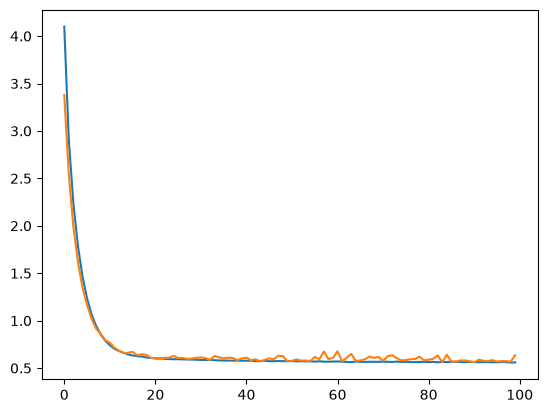

In [334]:
model1111 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1111.compile(
    optimizer=SGD(learning_rate=0.01),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro1111 = model1111.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1111.summary()

y_tr_1111 = le.inverse_transform(np.argmax(model1111.predict(x2_train_scaled), axis=1))
y_te_1111 = le.inverse_transform(np.argmax(model1111.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr_1111):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te_1111):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te_1111,
        target_names=labels_1
    )
)

plt.plot(cerebro1111.history['loss'])
plt.plot(cerebro1111.history['val_loss'])
print('accuracity ',cerebro1111.history['accuracy'][-1])
print('val_accuracy ',cerebro1111.history['val_accuracy'][-1])
print('loss ',cerebro1111.history['loss'][-1])
print('val_loss ',cerebro1111.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5691 - loss: 4.2738 - val_accuracy: 0.7181 - val_loss: 3.7576
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7303 - loss: 3.4863 - val_accuracy: 0.7556 - val_loss: 3.2392
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7603 - loss: 3.0234 - val_accuracy: 0.7569 - val_loss: 2.8481
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7772 - loss: 2.6545 - val_accuracy: 0.7706 - val_loss: 2.5005
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7783 - loss: 2.3489 - val_accuracy: 0.7781 - val_loss: 2.2188
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7873 - loss: 2.0854 - val_accuracy: 0.7681 - val_loss: 2.0058
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7939 - loss: 1.8700 - val_accuracy: 0.7812 - val_loss: 1.7826
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7966 - loss: 1.6826 - val_accu

Model: "sequential_48"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_294 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_295 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_296 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_297 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_298 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_299 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8142
A exactitude de predición da rede neuronal no conxunto de teste é 0.8013

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.81      0.77       443
   Moderate Crash & Lethargy       0.78      0.77      0.77       509
  Severe Crash & Tachycardia       0.88      0.89      0.89       435
Sustained / Negligible Crash       0.87      0.69      0.77       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8071874976158142
val_accuracy  0.8012499809265137
loss  0.5535165071487427
val_loss  0.5726212859153748


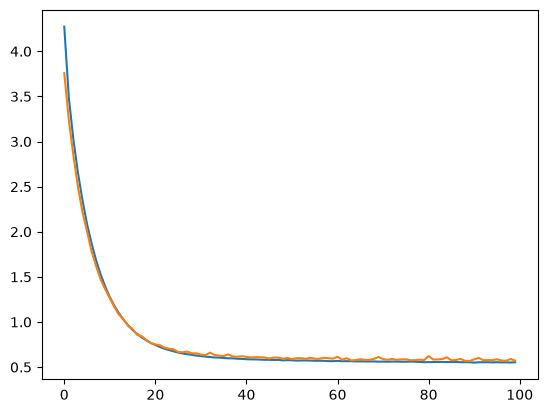

In [335]:
model1112 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1112.compile(
    optimizer=SGD(learning_rate=0.01),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro1112 = model1112.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1112.summary()

y_tr_1112 = le.inverse_transform(np.argmax(model1112.predict(x2_train_scaled), axis=1))
y_te_1112 = le.inverse_transform(np.argmax(model1112.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr_1112):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te_1112):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te_1112,
        target_names=labels_1
    )
)

plt.plot(cerebro1112.history['loss'])
plt.plot(cerebro1112.history['val_loss'])
print('accuracity ',cerebro1112.history['accuracy'][-1])
print('val_accuracy ',cerebro1112.history['val_accuracy'][-1])
print('loss ',cerebro1112.history['loss'][-1])
print('val_loss ',cerebro1112.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3366 - loss: 4.8519 - val_accuracy: 0.3981 - val_loss: 4.7288
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4208 - loss: 4.6372 - val_accuracy: 0.4588 - val_loss: 4.5406
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4686 - loss: 4.4508 - val_accuracy: 0.5113 - val_loss: 4.3531
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5170 - loss: 4.2692 - val_accuracy: 0.5525 - val_loss: 4.1705
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5530 - loss: 4.0906 - val_accuracy: 0.5719 - val_loss: 3.9972
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5888 - loss: 3.9167 - val_accuracy: 0.6119 - val_loss: 3.8328
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6348 - loss: 3.7533 - val_accuracy: 0.6625 - val_loss: 3.6757
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6714 - loss: 3.6051 - val_accu

Model: "sequential_49"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_300 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_301 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_302 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_303 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_304 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_305 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8189
A exactitude de predición da rede neuronal no conxunto de teste é 0.7956

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.77      0.76       443
   Moderate Crash & Lethargy       0.75      0.79      0.77       509
  Severe Crash & Tachycardia       0.91      0.83      0.87       435
Sustained / Negligible Crash       0.79      0.79      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8239062428474426
val_accuracy  0.7956249713897705
loss  0.7445683479309082
val_loss  0.7853598594665527


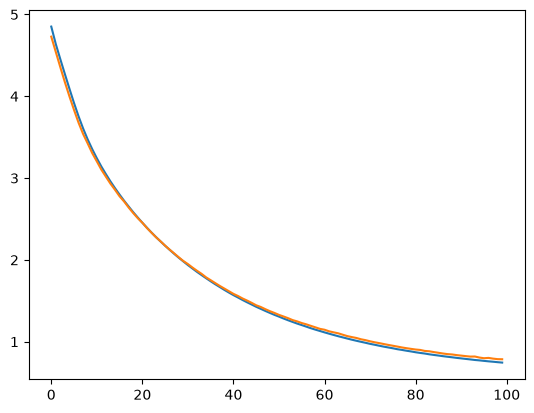

In [336]:
model1121 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1121.compile(
    optimizer=SGD(learning_rate=0.001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1121.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1121.summary()

y_tr = le.inverse_transform(np.argmax(model1121.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1121.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2684 - loss: 4.7945 - val_accuracy: 0.2937 - val_loss: 4.7369
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3088 - loss: 4.6919 - val_accuracy: 0.3281 - val_loss: 4.6575
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3455 - loss: 4.6171 - val_accuracy: 0.3738 - val_loss: 4.5834
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3772 - loss: 4.5454 - val_accuracy: 0.4075 - val_loss: 4.5099
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4056 - loss: 4.4731 - val_accuracy: 0.4313 - val_loss: 4.4351
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4297 - loss: 4.3970 - val_accuracy: 0.4525 - val_loss: 4.3557
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4567 - loss: 4.3164 - val_accuracy: 0.4681 - val_loss: 4.2698
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4778 - loss: 4.2311 - val_accu

Model: "sequential_50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_306 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_307 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_308 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_309 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_310 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_311 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8134
A exactitude de predición da rede neuronal no conxunto de teste é 0.7881

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.72      0.80      0.76       443
   Moderate Crash & Lethargy       0.76      0.75      0.76       509
  Severe Crash & Tachycardia       0.88      0.86      0.87       435
Sustained / Negligible Crash       0.82      0.72      0.77       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.8110937476158142
val_accuracy  0.7881249785423279
loss  1.2962486743927002
val_loss  1.3242998123168945


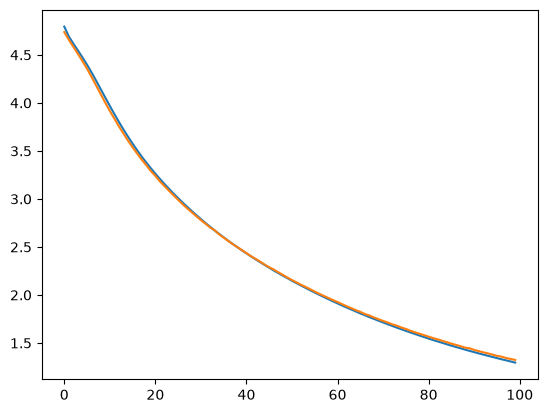

In [337]:
model1122 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1122.compile(
    optimizer=SGD(learning_rate=0.001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1122.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1122.summary()

y_tr = le.inverse_transform(np.argmax(model1122.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1122.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.1791 - loss: 4.9732 - val_accuracy: 0.2625 - val_loss: 4.8654
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2997 - loss: 4.8342 - val_accuracy: 0.3388 - val_loss: 4.7944
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3359 - loss: 4.7807 - val_accuracy: 0.3581 - val_loss: 4.7616
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3531 - loss: 4.7514 - val_accuracy: 0.3775 - val_loss: 4.7398
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3648 - loss: 4.7299 - val_accuracy: 0.3800 - val_loss: 4.7213
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3731 - loss: 4.7112 - val_accuracy: 0.3844 - val_loss: 4.7037
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3780 - loss: 4.6937 - val_accuracy: 0.3913 - val_loss: 4.6866
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3837 - loss: 4.6765 - val_accu

Model: "sequential_51"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_312 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_313 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_314 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_315 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_316 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_317 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7452
A exactitude de predición da rede neuronal no conxunto de teste é 0.7506

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.67      0.74      0.71       443
   Moderate Crash & Lethargy       0.71      0.71      0.71       509
  Severe Crash & Tachycardia       0.86      0.84      0.85       435
Sustained / Negligible Crash       0.82      0.68      0.74       213

                    accuracy                           0.75      1600
                   macro avg       0.77      0.74      0.75      1600
                weighted avg       0.76      0.75      0.75      1600

accuracity  0.7431250214576721
val_accuracy  0.7506250143051147
loss  3.1796512603759766
val_loss  3.175264358520508


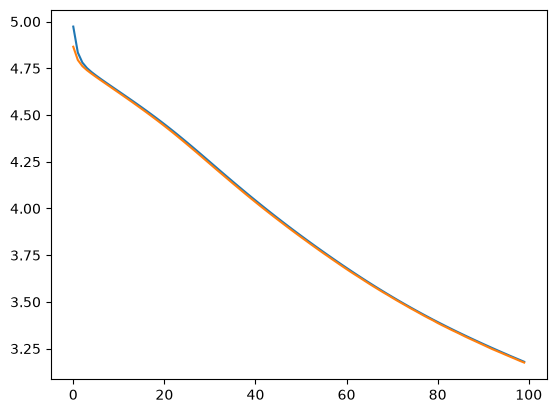

In [338]:
model1131 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1131.compile(
    optimizer=SGD(learning_rate=0.0001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1131.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1131.summary()

y_tr = le.inverse_transform(np.argmax(model1131.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1131.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2648 - loss: 5.0851 - val_accuracy: 0.2881 - val_loss: 4.9949
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2650 - loss: 4.9720 - val_accuracy: 0.2912 - val_loss: 4.9283
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2719 - loss: 4.9217 - val_accuracy: 0.3025 - val_loss: 4.8961
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2922 - loss: 4.8944 - val_accuracy: 0.3106 - val_loss: 4.8773
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3059 - loss: 4.8764 - val_accuracy: 0.3275 - val_loss: 4.8636
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3223 - loss: 4.8624 - val_accuracy: 0.3400 - val_loss: 4.8518
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3347 - loss: 4.8500 - val_accuracy: 0.3500 - val_loss: 4.8408
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3452 - loss: 4.8383 - val_accu

Model: "sequential_52"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_318 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_319 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_320 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_321 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_322 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_323 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.6436
A exactitude de predición da rede neuronal no conxunto de teste é 0.6338

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.58      0.75      0.66       443
   Moderate Crash & Lethargy       0.60      0.43      0.50       509
  Severe Crash & Tachycardia       0.67      0.76      0.71       435
Sustained / Negligible Crash       0.78      0.61      0.68       213

                    accuracy                           0.63      1600
                   macro avg       0.66      0.64      0.64      1600
                weighted avg       0.64      0.63      0.63      1600

accuracity  0.6420312523841858
val_accuracy  0.6337500214576721
loss  3.9088079929351807
val_loss  3.9139504432678223


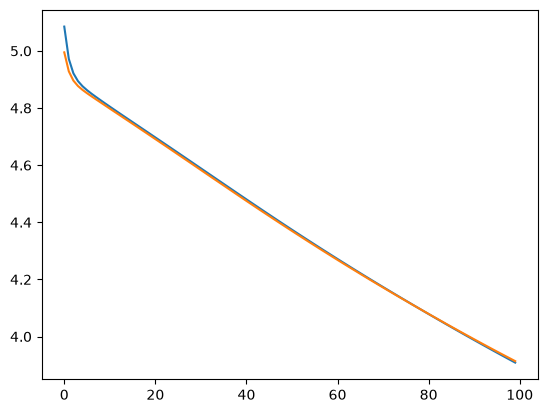

In [339]:
model1132 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1132.compile(
    optimizer=SGD(learning_rate=0.0001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1132.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1132.summary()

y_tr = le.inverse_transform(np.argmax(model1132.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1132.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5794 - loss: 3.9219 - val_accuracy: 0.7312 - val_loss: 3.2030
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7544 - loss: 2.8192 - val_accuracy: 0.7563 - val_loss: 2.4707
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7677 - loss: 2.1996 - val_accuracy: 0.7394 - val_loss: 1.9987
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7852 - loss: 1.7618 - val_accuracy: 0.7756 - val_loss: 1.6048
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7887 - loss: 1.4501 - val_accuracy: 0.7812 - val_loss: 1.3404
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7912 - loss: 1.2267 - val_accuracy: 0.7844 - val_loss: 1.1432
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7941 - loss: 1.0657 - val_accuracy: 0.7875 - val_loss: 1.0146
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7975 - loss: 0.9436 - val_accu

Model: "sequential_53"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_324 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_325 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_326 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_327 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_328 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_329 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8030
A exactitude de predición da rede neuronal no conxunto de teste é 0.7800

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.75      0.75       443
   Moderate Crash & Lethargy       0.72      0.80      0.76       509
  Severe Crash & Tachycardia       0.93      0.76      0.84       435
Sustained / Negligible Crash       0.76      0.83      0.79       213

                    accuracy                           0.78      1600
                   macro avg       0.79      0.79      0.78      1600
                weighted avg       0.79      0.78      0.78      1600

accuracity  0.7917187213897705
val_accuracy  0.7799999713897705
loss  0.5630849003791809
val_loss  0.5907241702079773


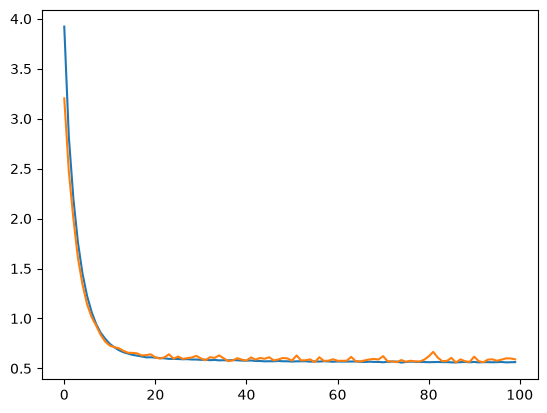

In [340]:
model1211 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1211.compile(
    optimizer=SGD(learning_rate=0.01, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1211.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1211.summary()

y_tr = le.inverse_transform(np.argmax(model1211.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1211.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5166 - loss: 4.4032 - val_accuracy: 0.6669 - val_loss: 3.8509
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7158 - loss: 3.5391 - val_accuracy: 0.7356 - val_loss: 3.2612
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7588 - loss: 3.0499 - val_accuracy: 0.7700 - val_loss: 2.8450
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7722 - loss: 2.6739 - val_accuracy: 0.7756 - val_loss: 2.5108
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7917 - loss: 2.3605 - val_accuracy: 0.7800 - val_loss: 2.2315
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7894 - loss: 2.0980 - val_accuracy: 0.7675 - val_loss: 2.0158
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7897 - loss: 1.8749 - val_accuracy: 0.7825 - val_loss: 1.8043
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7975 - loss: 1.6868 - val_accu

Model: "sequential_54"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_330 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_331 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_332 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_333 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_334 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_335 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8127
A exactitude de predición da rede neuronal no conxunto de teste é 0.7981

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.82      0.77       443
   Moderate Crash & Lethargy       0.76      0.78      0.77       509
  Severe Crash & Tachycardia       0.94      0.80      0.87       435
Sustained / Negligible Crash       0.80      0.78      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.80      0.80      1600
                weighted avg       0.81      0.80      0.80      1600

accuracity  0.8035937547683716
val_accuracy  0.7981250286102295
loss  0.5510406494140625
val_loss  0.5786006450653076


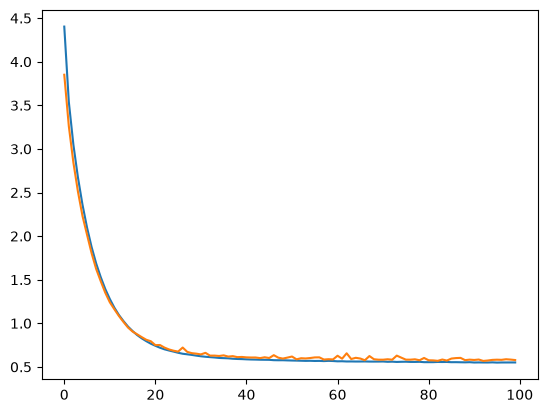

In [341]:
model1212 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1212.compile(
    optimizer=SGD(learning_rate=0.01, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1212.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1212.summary()

y_tr = le.inverse_transform(np.argmax(model1212.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1212.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3606 - loss: 4.8403 - val_accuracy: 0.4338 - val_loss: 4.6449
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4836 - loss: 4.5150 - val_accuracy: 0.5113 - val_loss: 4.3891
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5534 - loss: 4.2716 - val_accuracy: 0.5650 - val_loss: 4.1721
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6055 - loss: 4.0687 - val_accuracy: 0.6369 - val_loss: 3.9823
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6481 - loss: 3.8955 - val_accuracy: 0.6662 - val_loss: 3.8186
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6742 - loss: 3.7433 - val_accuracy: 0.6913 - val_loss: 3.6786
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6952 - loss: 3.6094 - val_accuracy: 0.7056 - val_loss: 3.5593
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7136 - loss: 3.4886 - val_accu

Model: "sequential_55"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_336 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_337 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_338 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_339 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_340 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_341 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8225
A exactitude de predición da rede neuronal no conxunto de teste é 0.7994

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.76      0.76       443
   Moderate Crash & Lethargy       0.75      0.80      0.78       509
  Severe Crash & Tachycardia       0.89      0.85      0.87       435
Sustained / Negligible Crash       0.83      0.76      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8178125023841858
val_accuracy  0.7993749976158142
loss  0.7408033013343811
val_loss  0.7705102562904358


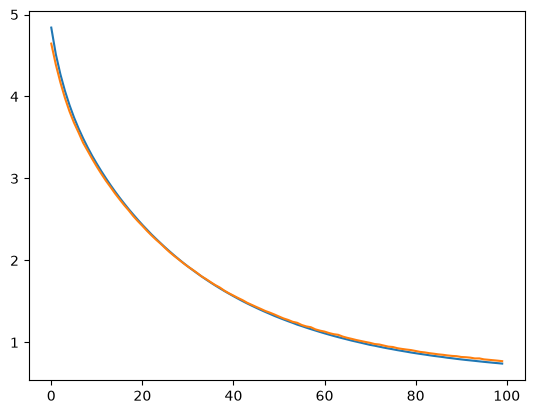

In [342]:
model1221 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1221.compile(
    optimizer=SGD(learning_rate=0.001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1221.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1221.summary()

y_tr = le.inverse_transform(np.argmax(model1221.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1221.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3105 - loss: 5.0040 - val_accuracy: 0.3825 - val_loss: 4.7503
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4320 - loss: 4.6728 - val_accuracy: 0.4544 - val_loss: 4.5885
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4878 - loss: 4.5055 - val_accuracy: 0.4969 - val_loss: 4.4274
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5236 - loss: 4.3559 - val_accuracy: 0.5281 - val_loss: 4.2965
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5733 - loss: 4.2327 - val_accuracy: 0.5819 - val_loss: 4.1840
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6092 - loss: 4.1235 - val_accuracy: 0.6119 - val_loss: 4.0811
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6323 - loss: 4.0216 - val_accuracy: 0.6431 - val_loss: 3.9799
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6580 - loss: 3.9264 - val_accu

Model: "sequential_56"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_342 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_343 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_344 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_345 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_346 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_347 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8113
A exactitude de predición da rede neuronal no conxunto de teste é 0.7956

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.78      0.76       443
   Moderate Crash & Lethargy       0.76      0.78      0.77       509
  Severe Crash & Tachycardia       0.88      0.88      0.88       435
Sustained / Negligible Crash       0.83      0.70      0.76       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8100000023841858
val_accuracy  0.7956249713897705
loss  1.3055593967437744
val_loss  1.325499415397644


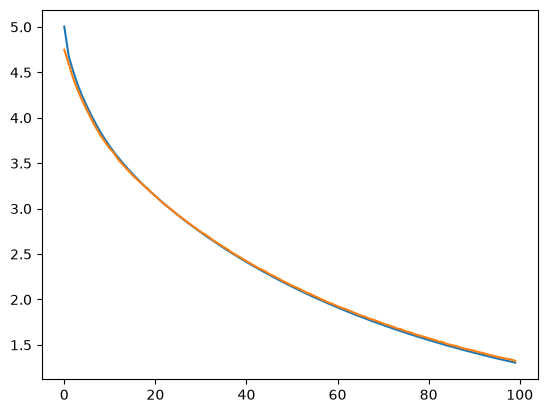

In [343]:
model1222 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1222.compile(
    optimizer=SGD(learning_rate=0.001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1222.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1222.summary()

y_tr = le.inverse_transform(np.argmax(model1222.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1222.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.1745 - loss: 5.1883 - val_accuracy: 0.2219 - val_loss: 5.0957
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2716 - loss: 5.0103 - val_accuracy: 0.2856 - val_loss: 4.9668
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3191 - loss: 4.9159 - val_accuracy: 0.3044 - val_loss: 4.8929
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3311 - loss: 4.8615 - val_accuracy: 0.3100 - val_loss: 4.8485
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3406 - loss: 4.8277 - val_accuracy: 0.3100 - val_loss: 4.8192
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3397 - loss: 4.8037 - val_accuracy: 0.3206 - val_loss: 4.7971
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3438 - loss: 4.7841 - val_accuracy: 0.3237 - val_loss: 4.7784
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3470 - loss: 4.7665 - val_accu

Model: "sequential_57"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_348 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_349 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_350 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_351 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_352 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_353 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7309
A exactitude de predición da rede neuronal no conxunto de teste é 0.7288

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.67      0.76      0.71       443
   Moderate Crash & Lethargy       0.69      0.65      0.67       509
  Severe Crash & Tachycardia       0.81      0.82      0.82       435
Sustained / Negligible Crash       0.80      0.67      0.73       213

                    accuracy                           0.73      1600
                   macro avg       0.74      0.72      0.73      1600
                weighted avg       0.73      0.73      0.73      1600

accuracity  0.7289062738418579
val_accuracy  0.7287499904632568
loss  3.2443532943725586
val_loss  3.2572548389434814


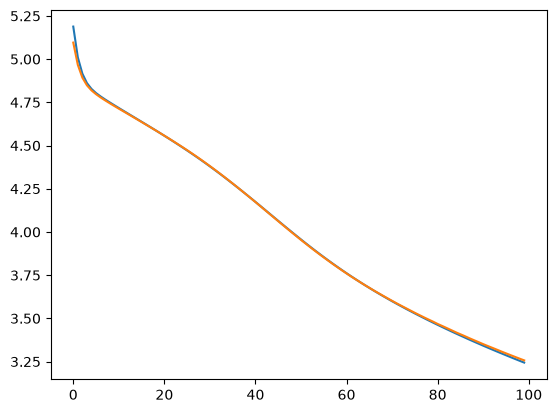

In [344]:
model1231 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1231.compile(
    optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1231.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1231.summary()

y_tr = le.inverse_transform(np.argmax(model1231.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1231.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3205 - loss: 5.0857 - val_accuracy: 0.2931 - val_loss: 4.9738
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3159 - loss: 4.8985 - val_accuracy: 0.2981 - val_loss: 4.8505
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3162 - loss: 4.8114 - val_accuracy: 0.2994 - val_loss: 4.7912
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3152 - loss: 4.7667 - val_accuracy: 0.2950 - val_loss: 4.7576
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3142 - loss: 4.7385 - val_accuracy: 0.3013 - val_loss: 4.7338
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3255 - loss: 4.7161 - val_accuracy: 0.3088 - val_loss: 4.7132
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3359 - loss: 4.6957 - val_accuracy: 0.3212 - val_loss: 4.6936
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3483 - loss: 4.6758 - val_accu

Model: "sequential_58"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_354 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_355 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_356 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_357 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_358 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_359 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7267
A exactitude de predición da rede neuronal no conxunto de teste é 0.7344

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.66      0.76      0.71       443
   Moderate Crash & Lethargy       0.72      0.64      0.68       509
  Severe Crash & Tachycardia       0.81      0.85      0.83       435
Sustained / Negligible Crash       0.79      0.68      0.73       213

                    accuracy                           0.73      1600
                   macro avg       0.75      0.73      0.74      1600
                weighted avg       0.74      0.73      0.73      1600

accuracity  0.7253124713897705
val_accuracy  0.734375
loss  3.2083160877227783
val_loss  3.225541353225708


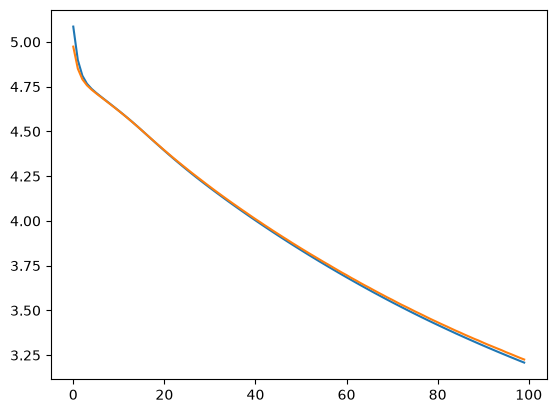

In [345]:
model1232 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1232.compile(
    optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1232.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1232.summary()

y_tr = le.inverse_transform(np.argmax(model1232.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1232.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6672 - loss: 1.0238 - val_accuracy: 0.7344 - val_loss: 0.7555
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7353 - loss: 0.7329 - val_accuracy: 0.7056 - val_loss: 0.8036
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7414 - loss: 0.6981 - val_accuracy: 0.6775 - val_loss: 0.8644
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7508 - loss: 0.6776 - val_accuracy: 0.7675 - val_loss: 0.6665
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7616 - loss: 0.6599 - val_accuracy: 0.7431 - val_loss: 0.6922
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7583 - loss: 0.6460 - val_accuracy: 0.7231 - val_loss: 0.7298
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7617 - loss: 0.6382 - val_accuracy: 0.7619 - val_loss: 0.6229
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7678 - loss: 0.6314 - val_accu

Model: "sequential_59"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_360 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_361 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_362 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_363 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_364 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_365 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7819
A exactitude de predición da rede neuronal no conxunto de teste é 0.7725

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.71      0.76      0.74       443
   Moderate Crash & Lethargy       0.74      0.74      0.74       509
  Severe Crash & Tachycardia       0.85      0.88      0.86       435
Sustained / Negligible Crash       0.84      0.66      0.74       213

                    accuracy                           0.77      1600
                   macro avg       0.79      0.76      0.77      1600
                weighted avg       0.78      0.77      0.77      1600

accuracity  0.7682812213897705
val_accuracy  0.7724999785423279
loss  0.5913049578666687
val_loss  0.5748313665390015


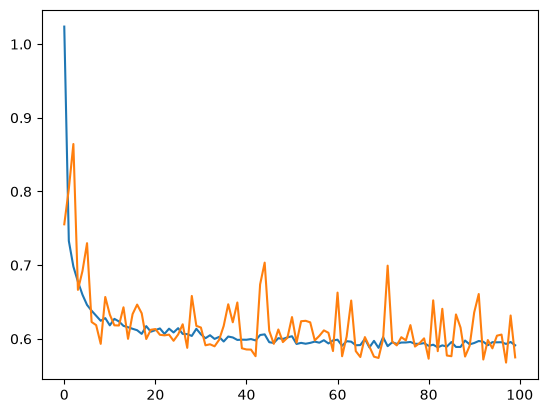

In [346]:
model1311 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1311.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.01),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1311.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1311.summary()

y_tr = le.inverse_transform(np.argmax(model1311.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1311.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6948 - loss: 1.1071 - val_accuracy: 0.6513 - val_loss: 0.9358
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7441 - loss: 0.7621 - val_accuracy: 0.7600 - val_loss: 0.7282
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7531 - loss: 0.7343 - val_accuracy: 0.7244 - val_loss: 0.7611
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7520 - loss: 0.7195 - val_accuracy: 0.7138 - val_loss: 0.7605
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7558 - loss: 0.7032 - val_accuracy: 0.7494 - val_loss: 0.7281
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7691 - loss: 0.6840 - val_accuracy: 0.7669 - val_loss: 0.6610
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7642 - loss: 0.6801 - val_accuracy: 0.7487 - val_loss: 0.7158
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7706 - loss: 0.6563 - val_accu

Model: "sequential_60"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_366 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_367 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_368 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_369 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_370 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_371 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7681
A exactitude de predición da rede neuronal no conxunto de teste é 0.7581

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.70      0.79      0.74       443
   Moderate Crash & Lethargy       0.70      0.77      0.73       509
  Severe Crash & Tachycardia       0.95      0.71      0.81       435
Sustained / Negligible Crash       0.76      0.78      0.77       213

                    accuracy                           0.76      1600
                   macro avg       0.78      0.76      0.76      1600
                weighted avg       0.77      0.76      0.76      1600

accuracity  0.7767187356948853
val_accuracy  0.7581250071525574
loss  0.5764096975326538
val_loss  0.6215065121650696


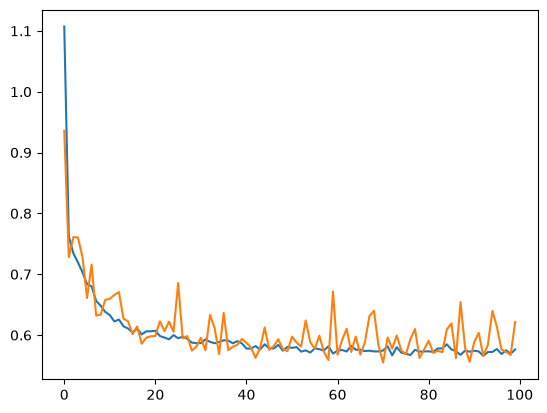

In [347]:
model1312 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1312.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.01),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1312.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1312.summary()

y_tr = le.inverse_transform(np.argmax(model1312.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1312.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6683 - loss: 2.5784 - val_accuracy: 0.7706 - val_loss: 1.4598
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7778 - loss: 1.1525 - val_accuracy: 0.7481 - val_loss: 1.0119
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7928 - loss: 0.8613 - val_accuracy: 0.7856 - val_loss: 0.8016
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7917 - loss: 0.7594 - val_accuracy: 0.7750 - val_loss: 0.7442
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7920 - loss: 0.7061 - val_accuracy: 0.7763 - val_loss: 0.7107
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7908 - loss: 0.6815 - val_accuracy: 0.7825 - val_loss: 0.6788
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7977 - loss: 0.6628 - val_accuracy: 0.7962 - val_loss: 0.6558
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7998 - loss: 0.6475 - val_accu

Model: "sequential_61"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_372 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_373 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_374 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_375 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_376 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_377 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8122
A exactitude de predición da rede neuronal no conxunto de teste é 0.7994

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.75      0.75       443
   Moderate Crash & Lethargy       0.75      0.82      0.79       509
  Severe Crash & Tachycardia       0.90      0.86      0.88       435
Sustained / Negligible Crash       0.82      0.73      0.77       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8065624833106995
val_accuracy  0.7993749976158142
loss  0.537350058555603
val_loss  0.5509438514709473


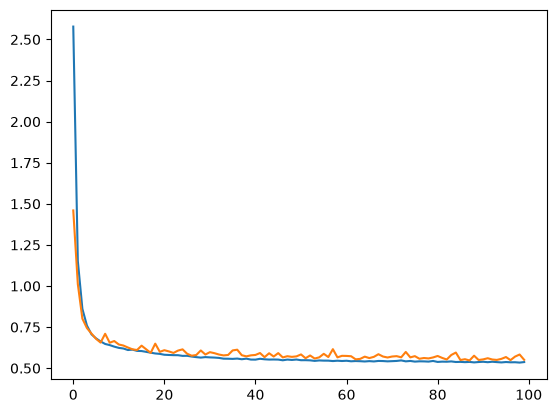

In [348]:
model1321 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1321.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1321.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1321.summary()

y_tr = le.inverse_transform(np.argmax(model1321.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1321.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6395 - loss: 2.9346 - val_accuracy: 0.7563 - val_loss: 1.8420
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7786 - loss: 1.4502 - val_accuracy: 0.7700 - val_loss: 1.1915
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7925 - loss: 1.0440 - val_accuracy: 0.7837 - val_loss: 0.9499
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7944 - loss: 0.8747 - val_accuracy: 0.7950 - val_loss: 0.8235
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8022 - loss: 0.7854 - val_accuracy: 0.7981 - val_loss: 0.7615
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7928 - loss: 0.7391 - val_accuracy: 0.7912 - val_loss: 0.7389
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7937 - loss: 0.7061 - val_accuracy: 0.7837 - val_loss: 0.7122
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7991 - loss: 0.6804 - val_accu

Model: "sequential_62"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_378 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_379 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_380 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_381 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_382 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_383 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7941
A exactitude de predición da rede neuronal no conxunto de teste é 0.7800

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.71      0.77      0.74       443
   Moderate Crash & Lethargy       0.73      0.82      0.77       509
  Severe Crash & Tachycardia       0.89      0.85      0.87       435
Sustained / Negligible Crash       0.90      0.56      0.69       213

                    accuracy                           0.78      1600
                   macro avg       0.81      0.75      0.77      1600
                weighted avg       0.79      0.78      0.78      1600

accuracity  0.8084375262260437
val_accuracy  0.7799999713897705
loss  0.5375065803527832
val_loss  0.5919582843780518


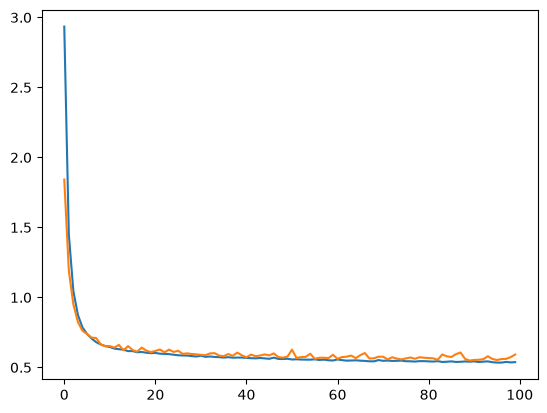

In [349]:
model1322 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1322.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1322.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1322.summary()

y_tr = le.inverse_transform(np.argmax(model1322.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1322.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3403 - loss: 4.3870 - val_accuracy: 0.4281 - val_loss: 3.9204
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5753 - loss: 3.4445 - val_accuracy: 0.6637 - val_loss: 3.0231
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7109 - loss: 2.7253 - val_accuracy: 0.7400 - val_loss: 2.4781
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7478 - loss: 2.3011 - val_accuracy: 0.7675 - val_loss: 2.1434
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7650 - loss: 2.0164 - val_accuracy: 0.7688 - val_loss: 1.9085
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7728 - loss: 1.8099 - val_accuracy: 0.7750 - val_loss: 1.7358
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7788 - loss: 1.6511 - val_accuracy: 0.7738 - val_loss: 1.5966
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7861 - loss: 1.5277 - val_accu

Model: "sequential_63"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_384 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_385 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_386 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_387 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_388 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_389 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8228
A exactitude de predición da rede neuronal no conxunto de teste é 0.8006

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.77      0.76       443
   Moderate Crash & Lethargy       0.76      0.80      0.78       509
  Severe Crash & Tachycardia       0.90      0.86      0.88       435
Sustained / Negligible Crash       0.82      0.76      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8160937428474426
val_accuracy  0.8006250262260437
loss  0.5834662318229675
val_loss  0.6138834953308105


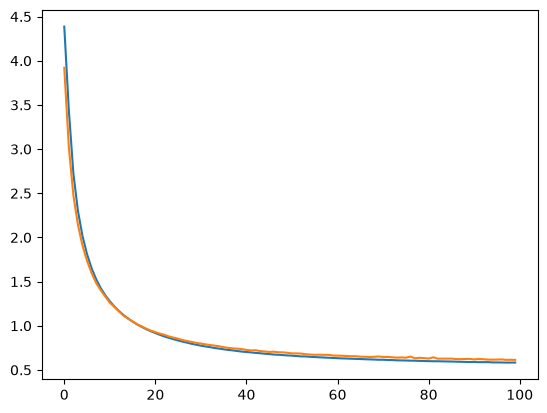

In [350]:
model1331 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1331.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1331.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1331.summary()

y_tr = le.inverse_transform(np.argmax(model1331.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1331.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3494 - loss: 4.7864 - val_accuracy: 0.4338 - val_loss: 4.4080
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4739 - loss: 4.1161 - val_accuracy: 0.5244 - val_loss: 3.8197
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5686 - loss: 3.5443 - val_accuracy: 0.6175 - val_loss: 3.2961
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6691 - loss: 3.0756 - val_accuracy: 0.6994 - val_loss: 2.8984
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7214 - loss: 2.7284 - val_accuracy: 0.7169 - val_loss: 2.6005
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7398 - loss: 2.4637 - val_accuracy: 0.7394 - val_loss: 2.3667
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7509 - loss: 2.2518 - val_accuracy: 0.7462 - val_loss: 2.1771
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7620 - loss: 2.0764 - val_accu

Model: "sequential_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_390 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_391 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_392 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_393 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_394 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_395 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8147
A exactitude de predición da rede neuronal no conxunto de teste é 0.7987

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.77      0.76       443
   Moderate Crash & Lethargy       0.75      0.82      0.78       509
  Severe Crash & Tachycardia       0.90      0.85      0.88       435
Sustained / Negligible Crash       0.84      0.70      0.77       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.817187488079071
val_accuracy  0.7987499833106995
loss  0.6166701316833496
val_loss  0.645528256893158


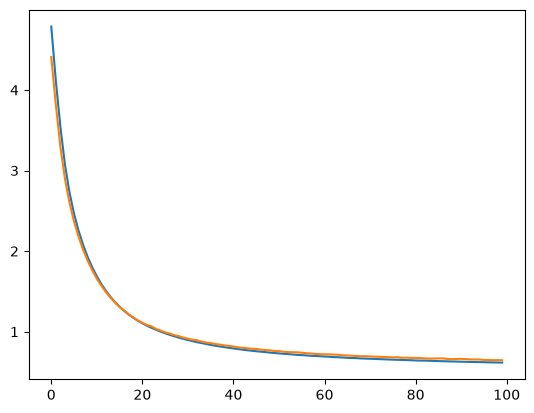

In [351]:
model1332 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1332.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1332.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1332.summary()

y_tr = le.inverse_transform(np.argmax(model1332.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1332.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6983 - loss: 1.0228 - val_accuracy: 0.7600 - val_loss: 0.7054
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7387 - loss: 0.7205 - val_accuracy: 0.7506 - val_loss: 0.6949
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7495 - loss: 0.6815 - val_accuracy: 0.6862 - val_loss: 0.8233
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7531 - loss: 0.6632 - val_accuracy: 0.7506 - val_loss: 0.6720
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7673 - loss: 0.6483 - val_accuracy: 0.7462 - val_loss: 0.6578
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7609 - loss: 0.6421 - val_accuracy: 0.7450 - val_loss: 0.6712
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7633 - loss: 0.6393 - val_accuracy: 0.7812 - val_loss: 0.6155
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7645 - loss: 0.6326 - val_accu

Model: "sequential_65"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_396 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_397 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_398 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_399 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_400 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_401 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7855
A exactitude de predición da rede neuronal no conxunto de teste é 0.7712

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.70      0.79      0.74       443
   Moderate Crash & Lethargy       0.74      0.73      0.73       509
  Severe Crash & Tachycardia       0.90      0.81      0.85       435
Sustained / Negligible Crash       0.79      0.75      0.77       213

                    accuracy                           0.77      1600
                   macro avg       0.78      0.77      0.77      1600
                weighted avg       0.78      0.77      0.77      1600

accuracity  0.7735937237739563
val_accuracy  0.7712500095367432
loss  0.5881616473197937
val_loss  0.5874080061912537


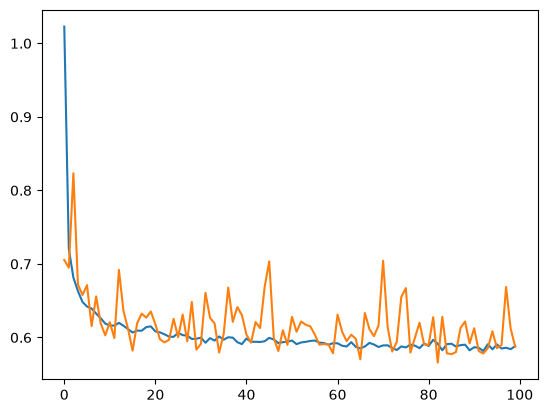

In [352]:
model1411 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1411.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1411.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1411.summary()

y_tr = le.inverse_transform(np.argmax(model1411.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1411.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7141 - loss: 1.1818 - val_accuracy: 0.7331 - val_loss: 0.8088
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7427 - loss: 0.7379 - val_accuracy: 0.7450 - val_loss: 0.7306
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7597 - loss: 0.6858 - val_accuracy: 0.7462 - val_loss: 0.6757
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7606 - loss: 0.6597 - val_accuracy: 0.7525 - val_loss: 0.6695
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7711 - loss: 0.6367 - val_accuracy: 0.7837 - val_loss: 0.6225
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7673 - loss: 0.6313 - val_accuracy: 0.7731 - val_loss: 0.6395
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7686 - loss: 0.6268 - val_accuracy: 0.7744 - val_loss: 0.6414
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7755 - loss: 0.6131 - val_accu

Model: "sequential_66"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_402 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_403 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_404 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_405 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_406 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_407 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7952
A exactitude de predición da rede neuronal no conxunto de teste é 0.7925

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.78      0.76       443
   Moderate Crash & Lethargy       0.78      0.72      0.75       509
  Severe Crash & Tachycardia       0.86      0.89      0.87       435
Sustained / Negligible Crash       0.79      0.79      0.79       213

                    accuracy                           0.79      1600
                   macro avg       0.79      0.80      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.7864062786102295
val_accuracy  0.7925000190734863
loss  0.5674532651901245
val_loss  0.561410665512085


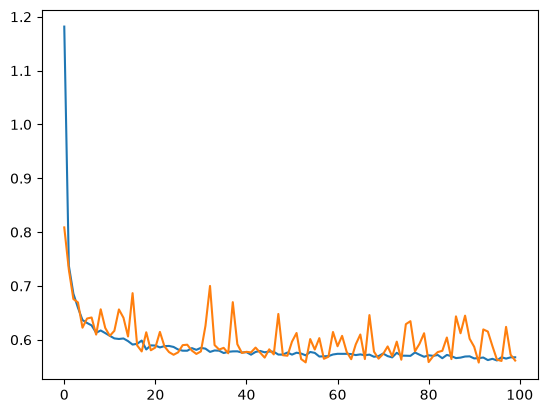

In [353]:
model1412 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1412.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1412.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1412.summary()

y_tr = le.inverse_transform(np.argmax(model1412.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1412.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6637 - loss: 2.3020 - val_accuracy: 0.7763 - val_loss: 1.2766
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7794 - loss: 1.0384 - val_accuracy: 0.7738 - val_loss: 0.9194
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7905 - loss: 0.8223 - val_accuracy: 0.7837 - val_loss: 0.7714
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7939 - loss: 0.7376 - val_accuracy: 0.7750 - val_loss: 0.7389
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7947 - loss: 0.6941 - val_accuracy: 0.7806 - val_loss: 0.7083
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7934 - loss: 0.6716 - val_accuracy: 0.7800 - val_loss: 0.6883
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7936 - loss: 0.6559 - val_accuracy: 0.7931 - val_loss: 0.6487
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7911 - loss: 0.6466 - val_accu

Model: "sequential_67"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_408 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_409 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_410 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_411 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_412 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_413 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7933
A exactitude de predición da rede neuronal no conxunto de teste é 0.7750

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.70      0.84      0.76       443
   Moderate Crash & Lethargy       0.72      0.74      0.73       509
  Severe Crash & Tachycardia       0.95      0.75      0.84       435
Sustained / Negligible Crash       0.82      0.77      0.80       213

                    accuracy                           0.78      1600
                   macro avg       0.80      0.78      0.78      1600
                weighted avg       0.79      0.78      0.78      1600

accuracity  0.8048437237739563
val_accuracy  0.7749999761581421
loss  0.5325219631195068
val_loss  0.6057884693145752


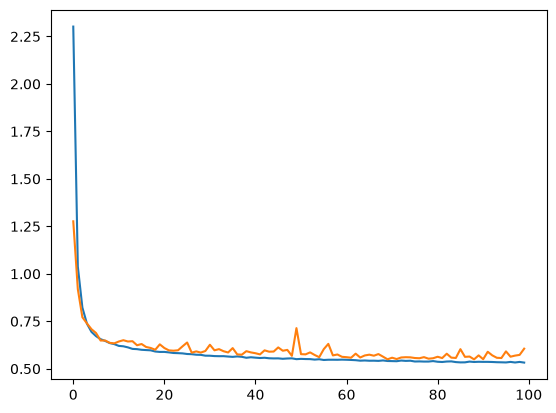

In [354]:
model1421 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1421.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1421.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1421.summary()

y_tr = le.inverse_transform(np.argmax(model1421.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1421.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6164 - loss: 3.0624 - val_accuracy: 0.7600 - val_loss: 1.8923
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7784 - loss: 1.4842 - val_accuracy: 0.7738 - val_loss: 1.2003
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7883 - loss: 1.0503 - val_accuracy: 0.7788 - val_loss: 0.9602
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7950 - loss: 0.8739 - val_accuracy: 0.7825 - val_loss: 0.8396
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7945 - loss: 0.7851 - val_accuracy: 0.7738 - val_loss: 0.7828
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7961 - loss: 0.7324 - val_accuracy: 0.7794 - val_loss: 0.7301
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7972 - loss: 0.6956 - val_accuracy: 0.7881 - val_loss: 0.6919
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8020 - loss: 0.6729 - val_accu

Model: "sequential_68"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_414 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_415 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_416 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_417 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_418 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_419 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8008
A exactitude de predición da rede neuronal no conxunto de teste é 0.7869

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.74      0.75       443
   Moderate Crash & Lethargy       0.76      0.73      0.75       509
  Severe Crash & Tachycardia       0.82      0.93      0.87       435
Sustained / Negligible Crash       0.84      0.72      0.78       213

                    accuracy                           0.79      1600
                   macro avg       0.79      0.78      0.79      1600
                weighted avg       0.79      0.79      0.78      1600

accuracity  0.8131250143051147
val_accuracy  0.7868750095367432
loss  0.5355342626571655
val_loss  0.5773438811302185


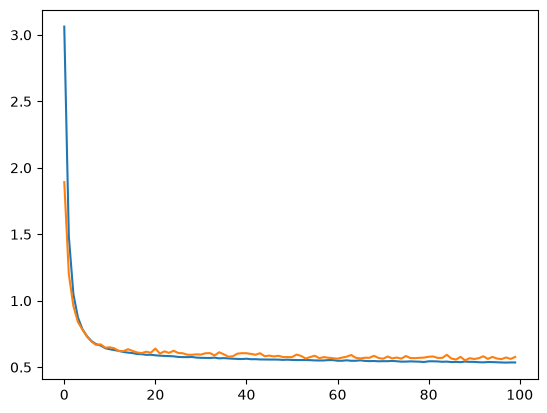

In [355]:
model1422 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1422.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1422.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1422.summary()

y_tr = le.inverse_transform(np.argmax(model1422.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1422.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.4172 - loss: 4.6201 - val_accuracy: 0.5125 - val_loss: 4.1125
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5672 - loss: 3.7319 - val_accuracy: 0.6125 - val_loss: 3.4118
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6564 - loss: 3.1144 - val_accuracy: 0.6862 - val_loss: 2.8910
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7119 - loss: 2.6661 - val_accuracy: 0.7337 - val_loss: 2.5014
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7617 - loss: 2.3374 - val_accuracy: 0.7650 - val_loss: 2.2226
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7734 - loss: 2.0917 - val_accuracy: 0.7844 - val_loss: 2.0003
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7825 - loss: 1.9009 - val_accuracy: 0.7931 - val_loss: 1.8309
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7870 - loss: 1.7502 - val_accu

Model: "sequential_69"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_420 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_421 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_422 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_423 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_424 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_425 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8216
A exactitude de predición da rede neuronal no conxunto de teste é 0.7919

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.80      0.76       443
   Moderate Crash & Lethargy       0.75      0.77      0.76       509
  Severe Crash & Tachycardia       0.93      0.81      0.86       435
Sustained / Negligible Crash       0.80      0.79      0.80       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.79      0.80      1600
                weighted avg       0.80      0.79      0.79      1600

accuracity  0.8212500214576721
val_accuracy  0.7918750047683716
loss  0.5902012586593628
val_loss  0.6351242661476135


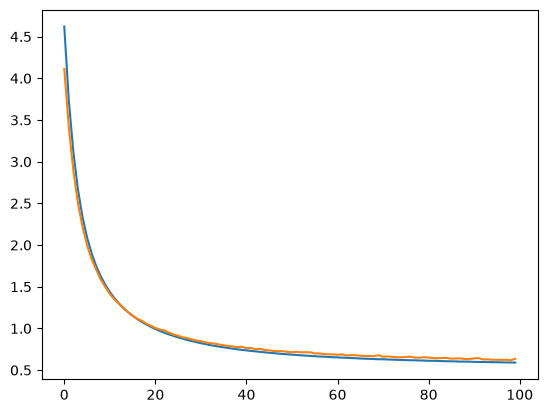

In [356]:
model1431 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1431.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.0001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1431.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1431.summary()

y_tr = le.inverse_transform(np.argmax(model1431.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1431.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2070 - loss: 4.8199 - val_accuracy: 0.3587 - val_loss: 4.3778
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3891 - loss: 4.0962 - val_accuracy: 0.4700 - val_loss: 3.7915
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5284 - loss: 3.5142 - val_accuracy: 0.5825 - val_loss: 3.2291
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6430 - loss: 2.9992 - val_accuracy: 0.6744 - val_loss: 2.7987
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7111 - loss: 2.6260 - val_accuracy: 0.7212 - val_loss: 2.4887
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7411 - loss: 2.3519 - val_accuracy: 0.7356 - val_loss: 2.2573
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7547 - loss: 2.1398 - val_accuracy: 0.7469 - val_loss: 2.0683
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7619 - loss: 1.9704 - val_accu

Model: "sequential_70"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_426 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_427 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_428 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_429 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_430 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_431 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8211
A exactitude de predición da rede neuronal no conxunto de teste é 0.7944

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.79      0.76       443
   Moderate Crash & Lethargy       0.76      0.78      0.77       509
  Severe Crash & Tachycardia       0.89      0.84      0.87       435
Sustained / Negligible Crash       0.82      0.74      0.78       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.79      0.79      1600
                weighted avg       0.80      0.79      0.80      1600

accuracity  0.8189062476158142
val_accuracy  0.7943750023841858
loss  0.6226686835289001
val_loss  0.6590229868888855


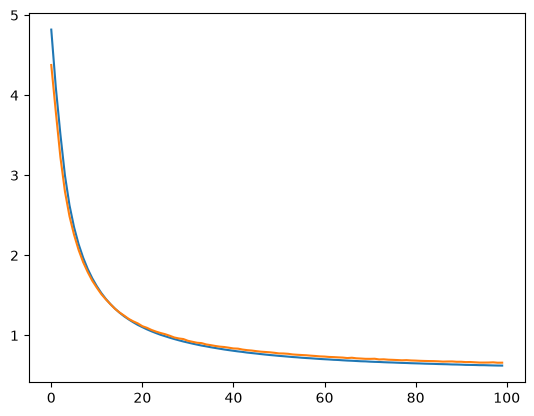

In [357]:
model1432 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1432.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.0001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1432.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1432.summary()

y_tr = le.inverse_transform(np.argmax(model1432.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1432.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6573 - loss: 2.2555 - val_accuracy: 0.7744 - val_loss: 1.2649
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7733 - loss: 1.0402 - val_accuracy: 0.7663 - val_loss: 0.9204
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7792 - loss: 0.8261 - val_accuracy: 0.7919 - val_loss: 0.7693
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7906 - loss: 0.7386 - val_accuracy: 0.7931 - val_loss: 0.7125
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7836 - loss: 0.6979 - val_accuracy: 0.7956 - val_loss: 0.6804
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7937 - loss: 0.6700 - val_accuracy: 0.7875 - val_loss: 0.6626
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7936 - loss: 0.6581 - val_accuracy: 0.7937 - val_loss: 0.6473
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7972 - loss: 0.6410 - val_accu

Model: "sequential_71"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_432 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_433 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_434 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_435 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_436 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_437 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8100
A exactitude de predición da rede neuronal no conxunto de teste é 0.7900

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.71      0.79      0.75       443
   Moderate Crash & Lethargy       0.78      0.72      0.75       509
  Severe Crash & Tachycardia       0.86      0.91      0.88       435
Sustained / Negligible Crash       0.84      0.70      0.76       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.8081250190734863
val_accuracy  0.7900000214576721
loss  0.5358545780181885
val_loss  0.5596721768379211


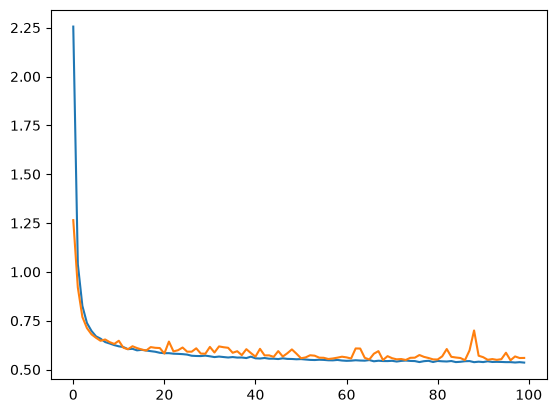

In [358]:
model1511 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1511.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1511.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1511.summary()

y_tr = le.inverse_transform(np.argmax(model1511.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1511.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6516 - loss: 2.8406 - val_accuracy: 0.7694 - val_loss: 1.7348
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7786 - loss: 1.3591 - val_accuracy: 0.7744 - val_loss: 1.1449
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7861 - loss: 0.9949 - val_accuracy: 0.7731 - val_loss: 0.9212
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7911 - loss: 0.8473 - val_accuracy: 0.7900 - val_loss: 0.8086
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7953 - loss: 0.7692 - val_accuracy: 0.7969 - val_loss: 0.7519
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7912 - loss: 0.7241 - val_accuracy: 0.7950 - val_loss: 0.7137
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7958 - loss: 0.6943 - val_accuracy: 0.7925 - val_loss: 0.6917
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7984 - loss: 0.6746 - val_accu

Model: "sequential_72"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_438 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_439 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_440 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_441 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_442 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_443 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8169
A exactitude de predición da rede neuronal no conxunto de teste é 0.7956

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.74      0.75       443
   Moderate Crash & Lethargy       0.74      0.81      0.77       509
  Severe Crash & Tachycardia       0.90      0.84      0.87       435
Sustained / Negligible Crash       0.82      0.77      0.80       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8057812452316284
val_accuracy  0.7956249713897705
loss  0.5382418036460876
val_loss  0.5513453483581543


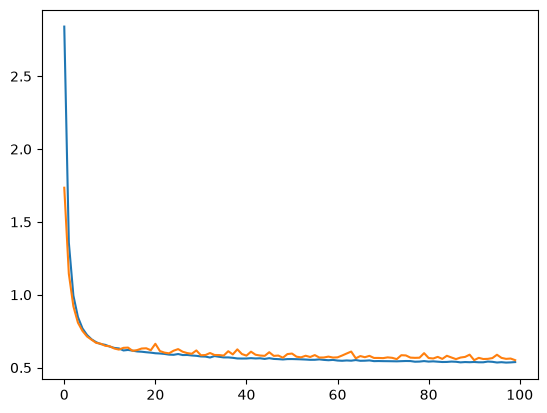

In [359]:
model1512 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1512.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1512.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1512.summary()

y_tr = le.inverse_transform(np.argmax(model1512.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1512.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7013 - loss: 1.2771 - val_accuracy: 0.7450 - val_loss: 0.7778
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7511 - loss: 0.7208 - val_accuracy: 0.7788 - val_loss: 0.6594
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7644 - loss: 0.6693 - val_accuracy: 0.7819 - val_loss: 0.6336
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7727 - loss: 0.6472 - val_accuracy: 0.7781 - val_loss: 0.6250
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7681 - loss: 0.6486 - val_accuracy: 0.7781 - val_loss: 0.6236
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7719 - loss: 0.6281 - val_accuracy: 0.7812 - val_loss: 0.6178
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7816 - loss: 0.6226 - val_accuracy: 0.7819 - val_loss: 0.6142
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7727 - loss: 0.6193 - val_accu

Model: "sequential_73"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_444 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_445 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_446 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_447 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_448 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_449 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7916
A exactitude de predición da rede neuronal no conxunto de teste é 0.7837

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.77      0.76       443
   Moderate Crash & Lethargy       0.76      0.71      0.73       509
  Severe Crash & Tachycardia       0.82      0.89      0.86       435
Sustained / Negligible Crash       0.83      0.76      0.79       213

                    accuracy                           0.78      1600
                   macro avg       0.79      0.78      0.79      1600
                weighted avg       0.78      0.78      0.78      1600

accuracity  0.7887499928474426
val_accuracy  0.7837499976158142
loss  0.5600219964981079
val_loss  0.5668206214904785


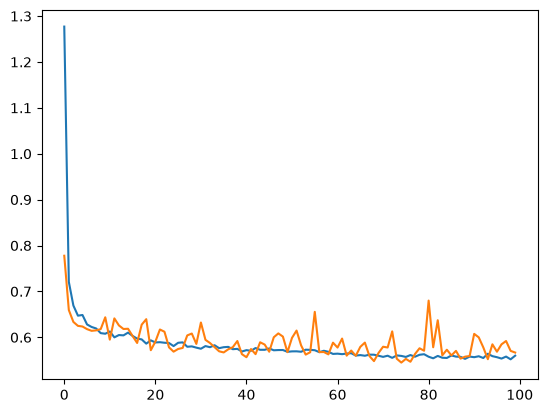

In [360]:
model1521 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1521.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.004, weight_decay=0.0002),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1521.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1521.summary()

y_tr = le.inverse_transform(np.argmax(model1521.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1521.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6861 - loss: 1.6363 - val_accuracy: 0.7794 - val_loss: 0.8380
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7642 - loss: 0.7794 - val_accuracy: 0.7175 - val_loss: 0.7983
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7659 - loss: 0.7176 - val_accuracy: 0.7769 - val_loss: 0.6845
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7736 - loss: 0.6775 - val_accuracy: 0.7669 - val_loss: 0.6832
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7733 - loss: 0.6737 - val_accuracy: 0.7806 - val_loss: 0.6450
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7756 - loss: 0.6561 - val_accuracy: 0.7950 - val_loss: 0.6207
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7777 - loss: 0.6459 - val_accuracy: 0.7794 - val_loss: 0.6480
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7730 - loss: 0.6357 - val_accu

Model: "sequential_74"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_450 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_451 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_452 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_453 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_454 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_455 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7975
A exactitude de predición da rede neuronal no conxunto de teste é 0.7863

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.77      0.74      0.75       443
   Moderate Crash & Lethargy       0.74      0.74      0.74       509
  Severe Crash & Tachycardia       0.85      0.86      0.86       435
Sustained / Negligible Crash       0.80      0.83      0.81       213

                    accuracy                           0.79      1600
                   macro avg       0.79      0.79      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.7925000190734863
val_accuracy  0.7862499952316284
loss  0.5430309176445007
val_loss  0.5619223713874817


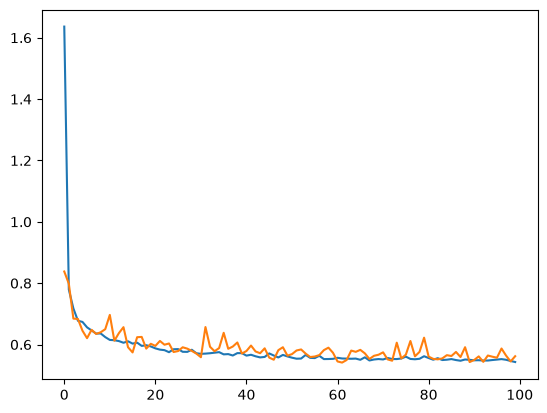

In [361]:
model1522 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model1522.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.004, weight_decay=0.0002),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model1522.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model1522.summary()

y_tr = le.inverse_transform(np.argmax(model1522.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model1522.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

parte 2, redes permutadas

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4956 - loss: 3.6837 - val_accuracy: 0.7050 - val_loss: 2.9482
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7344 - loss: 2.5626 - val_accuracy: 0.7200 - val_loss: 2.2912
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7677 - loss: 2.0061 - val_accuracy: 0.7506 - val_loss: 1.8210
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7803 - loss: 1.6206 - val_accuracy: 0.7856 - val_loss: 1.4703
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7828 - loss: 1.3494 - val_accuracy: 0.7725 - val_loss: 1.2599
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7869 - loss: 1.1573 - val_accuracy: 0.7775 - val_loss: 1.0969
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7858 - loss: 1.0136 - val_accuracy: 0.7731 - val_loss: 0.9851
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7925 - loss: 0.9060 - val_accu

Model: "sequential_75"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_456 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_457 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_458 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_459 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_460 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_461 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7936
A exactitude de predición da rede neuronal no conxunto de teste é 0.7850

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.72      0.78      0.75       443
   Moderate Crash & Lethargy       0.76      0.77      0.77       509
  Severe Crash & Tachycardia       0.85      0.90      0.87       435
Sustained / Negligible Crash       0.91      0.58      0.71       213

                    accuracy                           0.79      1600
                   macro avg       0.81      0.76      0.77      1600
                weighted avg       0.79      0.79      0.78      1600

accuracity  0.7873437404632568
val_accuracy  0.7850000262260437
loss  0.5812609195709229
val_loss  0.5906305909156799


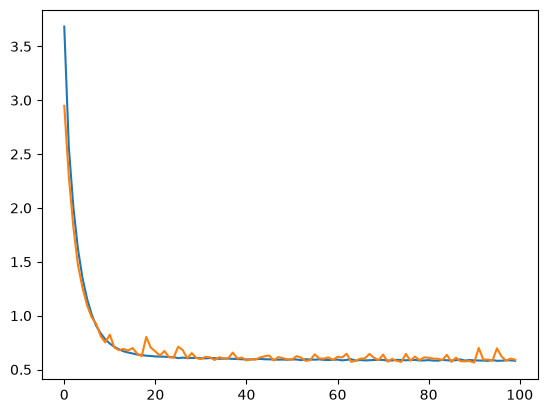

In [362]:
mode21111 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21111.compile(
    optimizer=SGD(learning_rate=0.01),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro1111 = mode21111.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21111.summary()

y_tr_1111 = le.inverse_transform(np.argmax(mode21111.predict(x2_train_scaled), axis=1))
y_te_1111 = le.inverse_transform(np.argmax(mode21111.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr_1111):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te_1111):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te_1111,
        target_names=labels_1
    )
)

plt.plot(cerebro1111.history['loss'])
plt.plot(cerebro1111.history['val_loss'])
print('accuracity ',cerebro1111.history['accuracy'][-1])
print('val_accuracy ',cerebro1111.history['val_accuracy'][-1])
print('loss ',cerebro1111.history['loss'][-1])
print('val_loss ',cerebro1111.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4861 - loss: 3.8736 - val_accuracy: 0.6194 - val_loss: 3.4309
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7047 - loss: 3.1031 - val_accuracy: 0.7425 - val_loss: 2.8650
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7558 - loss: 2.6533 - val_accuracy: 0.7531 - val_loss: 2.5114
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7778 - loss: 2.3330 - val_accuracy: 0.7444 - val_loss: 2.2575
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7858 - loss: 2.0698 - val_accuracy: 0.7788 - val_loss: 1.9722
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7933 - loss: 1.8466 - val_accuracy: 0.7688 - val_loss: 1.7852
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7930 - loss: 1.6637 - val_accuracy: 0.7844 - val_loss: 1.6071
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7942 - loss: 1.5072 - val_accu

Model: "sequential_76"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_462 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_463 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_464 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_465 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_466 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_467 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8150
A exactitude de predición da rede neuronal no conxunto de teste é 0.7981

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.75      0.75       443
   Moderate Crash & Lethargy       0.74      0.82      0.78       509
  Severe Crash & Tachycardia       0.91      0.84      0.87       435
Sustained / Negligible Crash       0.81      0.77      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.801562488079071
val_accuracy  0.7981250286102295
loss  0.5615761280059814
val_loss  0.5744945406913757


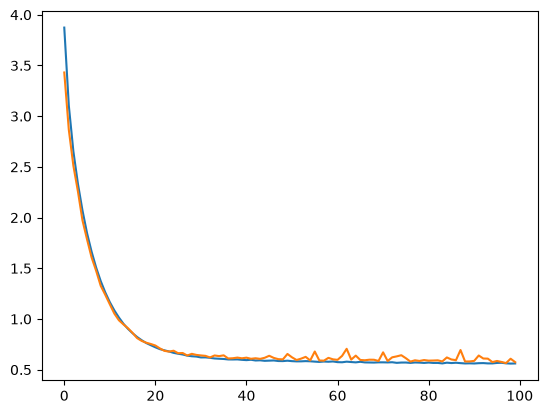

In [363]:
mode21112 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21112.compile(
    optimizer=SGD(learning_rate=0.01),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro1112 = mode21112.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21112.summary()

y_tr_1112 = le.inverse_transform(np.argmax(mode21112.predict(x2_train_scaled), axis=1))
y_te_1112 = le.inverse_transform(np.argmax(mode21112.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr_1112):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te_1112):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te_1112,
        target_names=labels_1
    )
)

plt.plot(cerebro1112.history['loss'])
plt.plot(cerebro1112.history['val_loss'])
print('accuracity ',cerebro1112.history['accuracy'][-1])
print('val_accuracy ',cerebro1112.history['val_accuracy'][-1])
print('loss ',cerebro1112.history['loss'][-1])
print('val_loss ',cerebro1112.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3114 - loss: 4.3058 - val_accuracy: 0.4025 - val_loss: 4.2028
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4236 - loss: 4.1063 - val_accuracy: 0.4744 - val_loss: 3.9876
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5119 - loss: 3.8745 - val_accuracy: 0.5700 - val_loss: 3.7524
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5819 - loss: 3.6478 - val_accuracy: 0.6156 - val_loss: 3.5599
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6441 - loss: 3.4663 - val_accuracy: 0.6712 - val_loss: 3.4005
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6894 - loss: 3.3177 - val_accuracy: 0.6969 - val_loss: 3.2644
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7103 - loss: 3.1918 - val_accuracy: 0.7113 - val_loss: 3.1572
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7258 - loss: 3.0824 - val_accu

Model: "sequential_77"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_468 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_469 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_470 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_471 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_472 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_473 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8180
A exactitude de predición da rede neuronal no conxunto de teste é 0.8025

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.78      0.77       443
   Moderate Crash & Lethargy       0.78      0.78      0.78       509
  Severe Crash & Tachycardia       0.88      0.87      0.88       435
Sustained / Negligible Crash       0.81      0.77      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8140624761581421
val_accuracy  0.8025000095367432
loss  0.7025735378265381
val_loss  0.7328503131866455


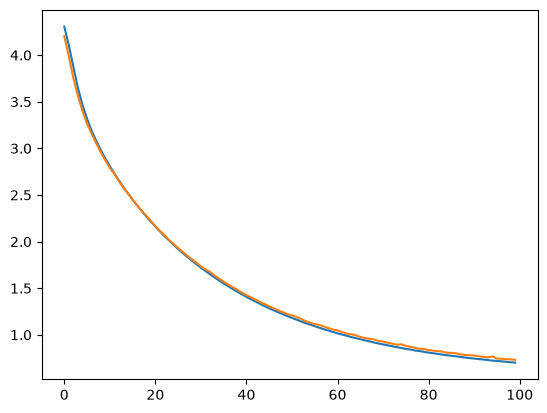

In [364]:
mode21121 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21121.compile(
    optimizer=SGD(learning_rate=0.001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21121.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21121.summary()

y_tr = le.inverse_transform(np.argmax(mode21121.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21121.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2586 - loss: 4.4232 - val_accuracy: 0.3044 - val_loss: 4.2710
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3512 - loss: 4.2191 - val_accuracy: 0.3519 - val_loss: 4.1770
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3789 - loss: 4.1362 - val_accuracy: 0.3875 - val_loss: 4.1001
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4081 - loss: 4.0581 - val_accuracy: 0.4056 - val_loss: 4.0203
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4253 - loss: 3.9729 - val_accuracy: 0.4331 - val_loss: 3.9319
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4586 - loss: 3.8822 - val_accuracy: 0.4638 - val_loss: 3.8375
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5027 - loss: 3.7838 - val_accuracy: 0.5113 - val_loss: 3.7390
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5502 - loss: 3.6828 - val_accu

Model: "sequential_78"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_474 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_475 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_476 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_477 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_478 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_479 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8150
A exactitude de predición da rede neuronal no conxunto de teste é 0.7956

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.77      0.76       443
   Moderate Crash & Lethargy       0.75      0.79      0.77       509
  Severe Crash & Tachycardia       0.89      0.85      0.87       435
Sustained / Negligible Crash       0.83      0.73      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.79      0.79      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8167187571525574
val_accuracy  0.7956249713897705
loss  1.181312918663025
val_loss  1.2101337909698486


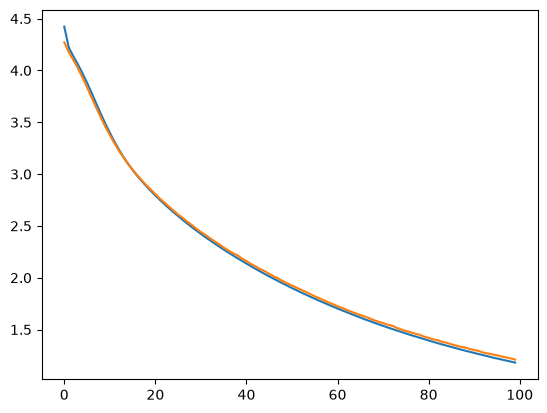

In [365]:
mode21122 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21122.compile(
    optimizer=SGD(learning_rate=0.001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21122.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21122.summary()

y_tr = le.inverse_transform(np.argmax(mode21122.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21122.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2852 - loss: 4.7960 - val_accuracy: 0.2744 - val_loss: 4.6932
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2667 - loss: 4.6174 - val_accuracy: 0.2912 - val_loss: 4.5661
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2848 - loss: 4.5258 - val_accuracy: 0.2981 - val_loss: 4.4969
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3005 - loss: 4.4720 - val_accuracy: 0.3181 - val_loss: 4.4553
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3200 - loss: 4.4354 - val_accuracy: 0.3269 - val_loss: 4.4241
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3398 - loss: 4.4060 - val_accuracy: 0.3506 - val_loss: 4.3969
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3639 - loss: 4.3794 - val_accuracy: 0.3681 - val_loss: 4.3708
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3750 - loss: 4.3542 - val_accu

Model: "sequential_79"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_480 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_481 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_482 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_483 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_484 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_485 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7627
A exactitude de predición da rede neuronal no conxunto de teste é 0.7550

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.70      0.77      0.73       443
   Moderate Crash & Lethargy       0.71      0.69      0.70       509
  Severe Crash & Tachycardia       0.84      0.82      0.83       435
Sustained / Negligible Crash       0.81      0.73      0.77       213

                    accuracy                           0.76      1600
                   macro avg       0.77      0.75      0.76      1600
                weighted avg       0.76      0.76      0.76      1600

accuracity  0.7632812261581421
val_accuracy  0.7549999952316284
loss  2.926647663116455
val_loss  2.9362289905548096


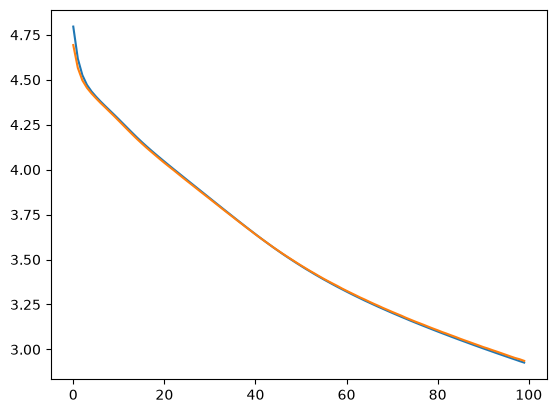

In [366]:
mode21131 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21131.compile(
    optimizer=SGD(learning_rate=0.0001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21131.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21131.summary()

y_tr = le.inverse_transform(np.argmax(mode21131.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21131.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2713 - loss: 4.4548 - val_accuracy: 0.3156 - val_loss: 4.3916
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2972 - loss: 4.3625 - val_accuracy: 0.3044 - val_loss: 4.3383
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2950 - loss: 4.3224 - val_accuracy: 0.2962 - val_loss: 4.3121
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3020 - loss: 4.3001 - val_accuracy: 0.2906 - val_loss: 4.2955
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3222 - loss: 4.2848 - val_accuracy: 0.3038 - val_loss: 4.2829
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3388 - loss: 4.2724 - val_accuracy: 0.3194 - val_loss: 4.2720
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3512 - loss: 4.2612 - val_accuracy: 0.3344 - val_loss: 4.2616
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3587 - loss: 4.2508 - val_accu

Model: "sequential_80"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_486 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_487 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_488 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_489 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_490 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_491 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.6567
A exactitude de predición da rede neuronal no conxunto de teste é 0.6438

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.57      0.70      0.63       443
   Moderate Crash & Lethargy       0.60      0.50      0.55       509
  Severe Crash & Tachycardia       0.71      0.79      0.75       435
Sustained / Negligible Crash       0.79      0.56      0.66       213

                    accuracy                           0.64      1600
                   macro avg       0.67      0.64      0.65      1600
                weighted avg       0.65      0.64      0.64      1600

accuracity  0.6548437476158142
val_accuracy  0.643750011920929
loss  3.3950326442718506
val_loss  3.4063854217529297


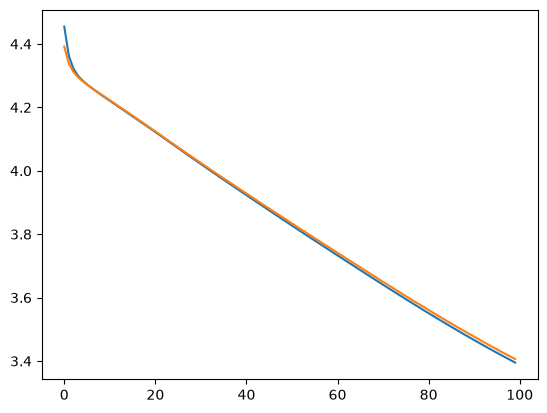

In [367]:
mode21132 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21132.compile(
    optimizer=SGD(learning_rate=0.0001),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21132.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21132.summary()

y_tr = le.inverse_transform(np.argmax(mode21132.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21132.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5816 - loss: 3.5195 - val_accuracy: 0.7219 - val_loss: 2.8881
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7339 - loss: 2.5466 - val_accuracy: 0.7344 - val_loss: 2.2668
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7692 - loss: 1.9946 - val_accuracy: 0.7581 - val_loss: 1.8109
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7823 - loss: 1.6156 - val_accuracy: 0.7700 - val_loss: 1.4908
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7880 - loss: 1.3400 - val_accuracy: 0.7325 - val_loss: 1.3308
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7884 - loss: 1.1497 - val_accuracy: 0.7750 - val_loss: 1.0939
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7939 - loss: 1.0058 - val_accuracy: 0.7681 - val_loss: 1.0044
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7867 - loss: 0.9042 - val_accu

Model: "sequential_81"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_492 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_493 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_494 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_495 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_496 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_497 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8097
A exactitude de predición da rede neuronal no conxunto de teste é 0.8031

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.79      0.76       443
   Moderate Crash & Lethargy       0.79      0.76      0.77       509
  Severe Crash & Tachycardia       0.88      0.89      0.89       435
Sustained / Negligible Crash       0.82      0.74      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.7881249785423279
val_accuracy  0.8031250238418579
loss  0.5844184160232544
val_loss  0.5599708557128906


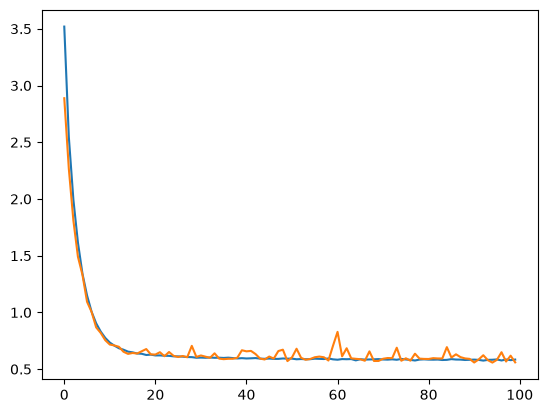

In [368]:
mode21211 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21211.compile(
    optimizer=SGD(learning_rate=0.01, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21211.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21211.summary()

y_tr = le.inverse_transform(np.argmax(mode21211.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21211.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4372 - loss: 3.9493 - val_accuracy: 0.5850 - val_loss: 3.5234
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6706 - loss: 3.1701 - val_accuracy: 0.7419 - val_loss: 2.8853
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7437 - loss: 2.6907 - val_accuracy: 0.7756 - val_loss: 2.5183
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7663 - loss: 2.3592 - val_accuracy: 0.7713 - val_loss: 2.2192
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7786 - loss: 2.0905 - val_accuracy: 0.7769 - val_loss: 1.9896
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7884 - loss: 1.8639 - val_accuracy: 0.7738 - val_loss: 1.7877
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7869 - loss: 1.6765 - val_accuracy: 0.7606 - val_loss: 1.6219
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7920 - loss: 1.5160 - val_accu

Model: "sequential_82"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_498 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_499 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_500 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_501 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_502 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_503 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8177
A exactitude de predición da rede neuronal no conxunto de teste é 0.8006

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.78      0.77       443
   Moderate Crash & Lethargy       0.76      0.80      0.78       509
  Severe Crash & Tachycardia       0.90      0.84      0.87       435
Sustained / Negligible Crash       0.81      0.77      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.797656238079071
val_accuracy  0.8006250262260437
loss  0.5661327242851257
val_loss  0.5692268013954163


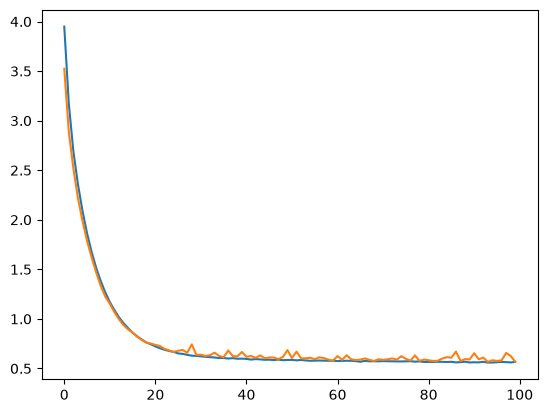

In [369]:
mode21212 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21212.compile(
    optimizer=SGD(learning_rate=0.01, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21212.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21212.summary()

y_tr = le.inverse_transform(np.argmax(mode21212.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21212.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2920 - loss: 4.3031 - val_accuracy: 0.3250 - val_loss: 4.2298
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3450 - loss: 4.1692 - val_accuracy: 0.4025 - val_loss: 4.1074
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4227 - loss: 4.0414 - val_accuracy: 0.4494 - val_loss: 3.9696
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4686 - loss: 3.8946 - val_accuracy: 0.5238 - val_loss: 3.8141
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5205 - loss: 3.7337 - val_accuracy: 0.5606 - val_loss: 3.6521
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5661 - loss: 3.5743 - val_accuracy: 0.5856 - val_loss: 3.5003
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6000 - loss: 3.4211 - val_accuracy: 0.6250 - val_loss: 3.3503
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6273 - loss: 3.2749 - val_accu

Model: "sequential_83"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_504 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_505 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_506 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_507 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_508 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_509 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8192
A exactitude de predición da rede neuronal no conxunto de teste é 0.7944

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.77      0.76       443
   Moderate Crash & Lethargy       0.74      0.80      0.77       509
  Severe Crash & Tachycardia       0.91      0.83      0.87       435
Sustained / Negligible Crash       0.82      0.76      0.79       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.79      0.80      1600
                weighted avg       0.80      0.79      0.80      1600

accuracity  0.8151562213897705
val_accuracy  0.7943750023841858
loss  0.7135604619979858
val_loss  0.7461815476417542


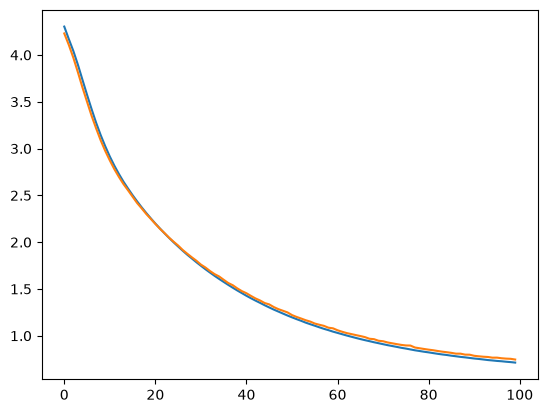

In [370]:
mode21221 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21221.compile(
    optimizer=SGD(learning_rate=0.001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21221.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21221.summary()

y_tr = le.inverse_transform(np.argmax(mode21221.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21221.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3427 - loss: 4.2877 - val_accuracy: 0.3625 - val_loss: 4.2438
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3898 - loss: 4.2028 - val_accuracy: 0.3919 - val_loss: 4.1799
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4338 - loss: 4.1377 - val_accuracy: 0.4250 - val_loss: 4.1140
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4509 - loss: 4.0715 - val_accuracy: 0.4456 - val_loss: 4.0481
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4772 - loss: 4.0036 - val_accuracy: 0.4719 - val_loss: 3.9834
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5008 - loss: 3.9322 - val_accuracy: 0.4925 - val_loss: 3.9129
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5128 - loss: 3.8587 - val_accuracy: 0.4969 - val_loss: 3.8326
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5227 - loss: 3.7816 - val_accu

Model: "sequential_84"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_510 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_511 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_513 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_514 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_515 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8161
A exactitude de predición da rede neuronal no conxunto de teste é 0.7900

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.79      0.76       443
   Moderate Crash & Lethargy       0.75      0.77      0.76       509
  Severe Crash & Tachycardia       0.87      0.86      0.86       435
Sustained / Negligible Crash       0.84      0.71      0.77       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.8142187595367432
val_accuracy  0.7900000214576721
loss  1.186522126197815
val_loss  1.2152953147888184


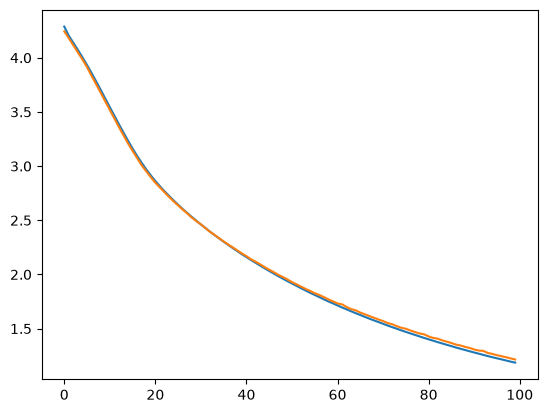

In [371]:
mode21222 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21222.compile(
    optimizer=SGD(learning_rate=0.001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21222.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21222.summary()

y_tr = le.inverse_transform(np.argmax(mode21222.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21222.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2716 - loss: 4.5092 - val_accuracy: 0.2875 - val_loss: 4.4526
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2919 - loss: 4.4225 - val_accuracy: 0.2900 - val_loss: 4.4020
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3167 - loss: 4.3825 - val_accuracy: 0.3156 - val_loss: 4.3709
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3367 - loss: 4.3545 - val_accuracy: 0.3456 - val_loss: 4.3465
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3539 - loss: 4.3306 - val_accuracy: 0.3606 - val_loss: 4.3242
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3739 - loss: 4.3083 - val_accuracy: 0.3738 - val_loss: 4.3033
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3933 - loss: 4.2871 - val_accuracy: 0.3844 - val_loss: 4.2826
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4000 - loss: 4.2671 - val_accu

Model: "sequential_85"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_516 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_517 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_518 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_519 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_520 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_521 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7364
A exactitude de predición da rede neuronal no conxunto de teste é 0.7275

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.65      0.74      0.69       443
   Moderate Crash & Lethargy       0.69      0.66      0.68       509
  Severe Crash & Tachycardia       0.83      0.83      0.83       435
Sustained / Negligible Crash       0.80      0.66      0.72       213

                    accuracy                           0.73      1600
                   macro avg       0.74      0.72      0.73      1600
                weighted avg       0.73      0.73      0.73      1600

accuracity  0.7332812547683716
val_accuracy  0.7275000214576721
loss  2.913811445236206
val_loss  2.935610771179199


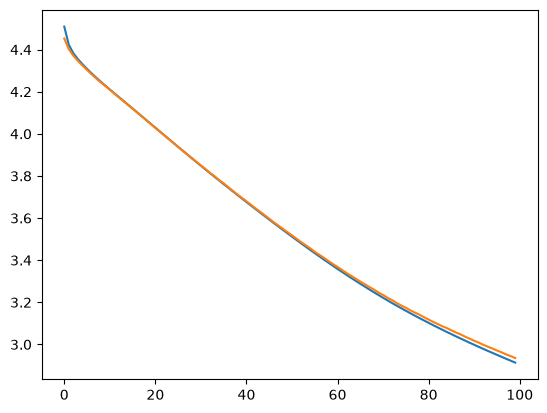

In [372]:
mode21231 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

mode21231.compile(
    optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = mode21231.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

mode21231.summary()

y_tr = le.inverse_transform(np.argmax(mode21231.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(mode21231.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2861 - loss: 4.5497 - val_accuracy: 0.2800 - val_loss: 4.4377
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3088 - loss: 4.3975 - val_accuracy: 0.3181 - val_loss: 4.3677
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3355 - loss: 4.3425 - val_accuracy: 0.3456 - val_loss: 4.3247
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3702 - loss: 4.3025 - val_accuracy: 0.3663 - val_loss: 4.2899
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3923 - loss: 4.2694 - val_accuracy: 0.3887 - val_loss: 4.2594
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4111 - loss: 4.2400 - val_accuracy: 0.3963 - val_loss: 4.2316
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4245 - loss: 4.2126 - val_accuracy: 0.4112 - val_loss: 4.2050
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4359 - loss: 4.1867 - val_accu

Model: "sequential_86"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_522 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_523 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_524 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_525 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_526 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_527 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,058 (23.67 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7580
A exactitude de predición da rede neuronal no conxunto de teste é 0.7462

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.68      0.75      0.71       443
   Moderate Crash & Lethargy       0.70      0.73      0.71       509
  Severe Crash & Tachycardia       0.88      0.78      0.83       435
Sustained / Negligible Crash       0.80      0.69      0.74       213

                    accuracy                           0.75      1600
                   macro avg       0.76      0.74      0.75      1600
                weighted avg       0.75      0.75      0.75      1600

accuracity  0.7562500238418579
val_accuracy  0.7462499737739563
loss  2.8236281871795654
val_loss  2.8489060401916504


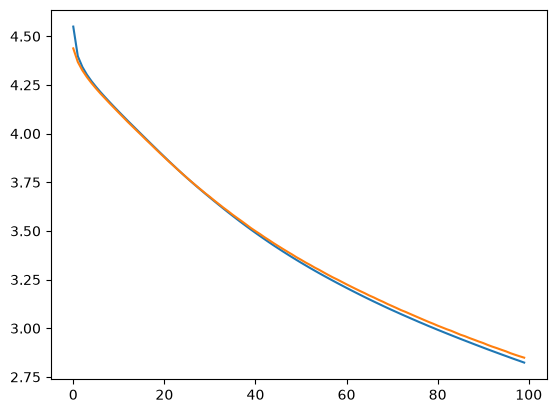

In [373]:
model2232 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2232.compile(
    optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2232.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2232.summary()

y_tr = le.inverse_transform(np.argmax(model2232.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2232.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6777 - loss: 1.0630 - val_accuracy: 0.6900 - val_loss: 0.8892
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7184 - loss: 0.7788 - val_accuracy: 0.7337 - val_loss: 0.7316
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7383 - loss: 0.7313 - val_accuracy: 0.7344 - val_loss: 0.7375
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7430 - loss: 0.7002 - val_accuracy: 0.6925 - val_loss: 0.7727
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7506 - loss: 0.6881 - val_accuracy: 0.7231 - val_loss: 0.7258
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7586 - loss: 0.6710 - val_accuracy: 0.7312 - val_loss: 0.7253
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7622 - loss: 0.6609 - val_accuracy: 0.7606 - val_loss: 0.6560
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7552 - loss: 0.6626 - val_accu

Model: "sequential_87"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_528 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_529 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_530 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_531 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_532 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_533 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7717
A exactitude de predición da rede neuronal no conxunto de teste é 0.7612

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.69      0.75      0.72       443
   Moderate Crash & Lethargy       0.72      0.73      0.73       509
  Severe Crash & Tachycardia       0.94      0.77      0.84       435
Sustained / Negligible Crash       0.73      0.84      0.78       213

                    accuracy                           0.76      1600
                   macro avg       0.77      0.77      0.77      1600
                weighted avg       0.77      0.76      0.76      1600

accuracity  0.7678124904632568
val_accuracy  0.7612500190734863
loss  0.5976888537406921
val_loss  0.6096768379211426


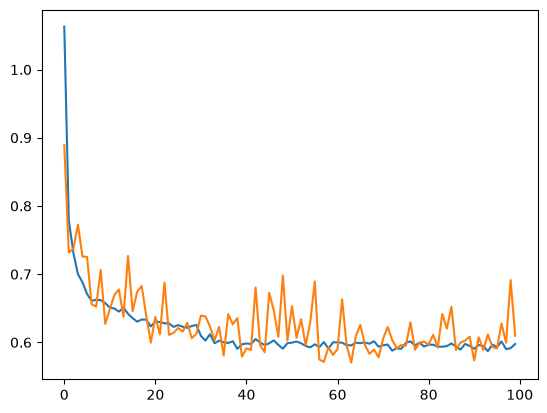

In [374]:
model2311 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2311.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.01),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2311.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2311.summary()

y_tr = le.inverse_transform(np.argmax(model2311.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2311.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6853 - loss: 1.1042 - val_accuracy: 0.7237 - val_loss: 0.8014
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7405 - loss: 0.7675 - val_accuracy: 0.7400 - val_loss: 0.7624
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7470 - loss: 0.7304 - val_accuracy: 0.6719 - val_loss: 0.8255
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7508 - loss: 0.7059 - val_accuracy: 0.7756 - val_loss: 0.6596
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7553 - loss: 0.6808 - val_accuracy: 0.7519 - val_loss: 0.6971
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7586 - loss: 0.6717 - val_accuracy: 0.7806 - val_loss: 0.6393
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7578 - loss: 0.6631 - val_accuracy: 0.7538 - val_loss: 0.6537
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7569 - loss: 0.6605 - val_accu

Model: "sequential_88"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_534 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_535 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_536 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_537 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_538 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_539 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7816
A exactitude de predición da rede neuronal no conxunto de teste é 0.7631

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.71      0.75      0.73       443
   Moderate Crash & Lethargy       0.72      0.72      0.72       509
  Severe Crash & Tachycardia       0.85      0.85      0.85       435
Sustained / Negligible Crash       0.80      0.74      0.77       213

                    accuracy                           0.76      1600
                   macro avg       0.77      0.76      0.77      1600
                weighted avg       0.76      0.76      0.76      1600

accuracity  0.7784374952316284
val_accuracy  0.7631250023841858
loss  0.5737271308898926
val_loss  0.5965654253959656


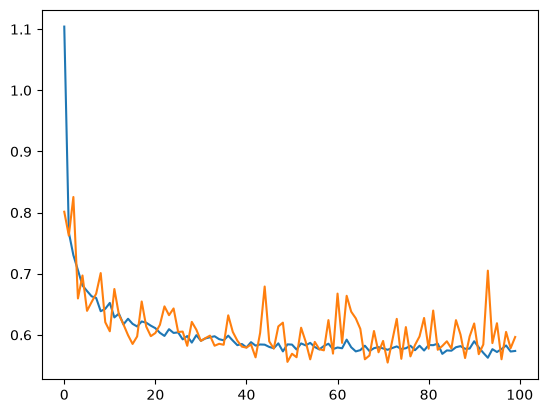

In [375]:
model2312 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2312.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.01),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2312.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2312.summary()

y_tr = le.inverse_transform(np.argmax(model2312.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2312.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6858 - loss: 2.1596 - val_accuracy: 0.7644 - val_loss: 1.3285
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7753 - loss: 1.1092 - val_accuracy: 0.7800 - val_loss: 0.9743
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7883 - loss: 0.8849 - val_accuracy: 0.7819 - val_loss: 0.8352
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7811 - loss: 0.7949 - val_accuracy: 0.7725 - val_loss: 0.7679
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7886 - loss: 0.7288 - val_accuracy: 0.7862 - val_loss: 0.7209
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7936 - loss: 0.6953 - val_accuracy: 0.7725 - val_loss: 0.7238
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7845 - loss: 0.6812 - val_accuracy: 0.8006 - val_loss: 0.6617
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7925 - loss: 0.6566 - val_accu

Model: "sequential_89"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_540 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_541 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_542 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_543 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_544 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_545 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8133
A exactitude de predición da rede neuronal no conxunto de teste é 0.7950

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.76      0.75       443
   Moderate Crash & Lethargy       0.78      0.75      0.77       509
  Severe Crash & Tachycardia       0.87      0.89      0.88       435
Sustained / Negligible Crash       0.78      0.78      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.79      0.80      0.79      1600
                weighted avg       0.79      0.80      0.79      1600

accuracity  0.809374988079071
val_accuracy  0.7950000166893005
loss  0.5250771045684814
val_loss  0.534187376499176


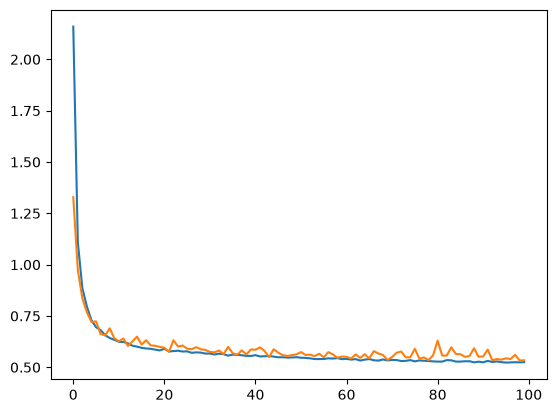

In [376]:
model2321 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2321.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2321.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2321.summary()

y_tr = le.inverse_transform(np.argmax(model2321.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2321.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6453 - loss: 2.5818 - val_accuracy: 0.7375 - val_loss: 1.7000
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7789 - loss: 1.3696 - val_accuracy: 0.7638 - val_loss: 1.1966
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7908 - loss: 1.0507 - val_accuracy: 0.7650 - val_loss: 1.0075
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7950 - loss: 0.9021 - val_accuracy: 0.7881 - val_loss: 0.8550
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7986 - loss: 0.8178 - val_accuracy: 0.7850 - val_loss: 0.7982
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8022 - loss: 0.7642 - val_accuracy: 0.7925 - val_loss: 0.7497
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7945 - loss: 0.7279 - val_accuracy: 0.7850 - val_loss: 0.7244
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7983 - loss: 0.6972 - val_accu

Model: "sequential_90"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_546 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_547 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_548 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_549 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_550 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_551 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8230
A exactitude de predición da rede neuronal no conxunto de teste é 0.8006

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.78      0.76       443
   Moderate Crash & Lethargy       0.77      0.79      0.78       509
  Severe Crash & Tachycardia       0.90      0.86      0.88       435
Sustained / Negligible Crash       0.80      0.76      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8126562237739563
val_accuracy  0.8006250262260437
loss  0.5215501189231873
val_loss  0.5323012471199036


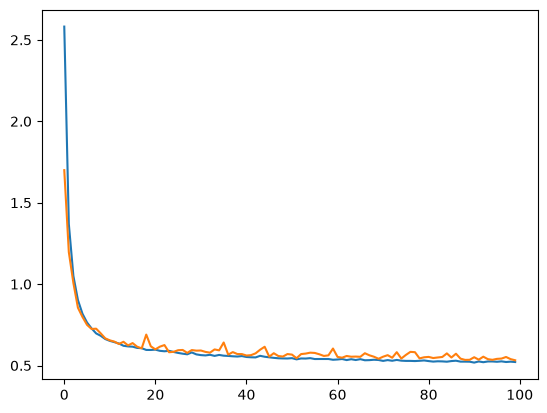

In [377]:
model2322 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2322.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2322.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2322.summary()

y_tr = le.inverse_transform(np.argmax(model2322.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2322.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4245 - loss: 3.9367 - val_accuracy: 0.5088 - val_loss: 3.5195
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5855 - loss: 3.1579 - val_accuracy: 0.6538 - val_loss: 2.8439
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6914 - loss: 2.6036 - val_accuracy: 0.7131 - val_loss: 2.4135
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7391 - loss: 2.2549 - val_accuracy: 0.7581 - val_loss: 2.1336
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7608 - loss: 2.0149 - val_accuracy: 0.7644 - val_loss: 1.9410
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7769 - loss: 1.8358 - val_accuracy: 0.7738 - val_loss: 1.7772
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7827 - loss: 1.6968 - val_accuracy: 0.7713 - val_loss: 1.6553
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7878 - loss: 1.5825 - val_accu

Model: "sequential_91"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_552 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_553 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_554 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_555 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_556 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_557 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8230
A exactitude de predición da rede neuronal no conxunto de teste é 0.7950

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.76      0.75       443
   Moderate Crash & Lethargy       0.76      0.79      0.77       509
  Severe Crash & Tachycardia       0.89      0.86      0.87       435
Sustained / Negligible Crash       0.80      0.76      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.79      0.79      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8214062452316284
val_accuracy  0.7950000166893005
loss  0.5811212658882141
val_loss  0.6121646761894226


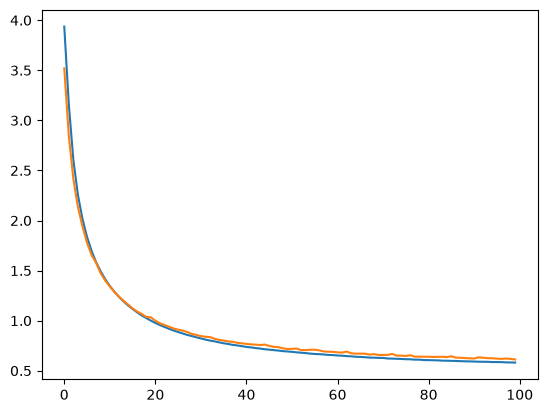

In [378]:
model2331 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2331.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2331.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2331.summary()

y_tr = le.inverse_transform(np.argmax(model2331.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2331.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3173 - loss: 4.2591 - val_accuracy: 0.4044 - val_loss: 3.8969
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4670 - loss: 3.6279 - val_accuracy: 0.5344 - val_loss: 3.3419
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6059 - loss: 3.0926 - val_accuracy: 0.6694 - val_loss: 2.8538
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6988 - loss: 2.6770 - val_accuracy: 0.7294 - val_loss: 2.5136
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7331 - loss: 2.3912 - val_accuracy: 0.7575 - val_loss: 2.2711
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7520 - loss: 2.1766 - val_accuracy: 0.7706 - val_loss: 2.0889
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7700 - loss: 2.0127 - val_accuracy: 0.7763 - val_loss: 1.9431
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7709 - loss: 1.8802 - val_accu

Model: "sequential_92"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_558 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_559 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_560 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_561 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_562 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_563 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8237
A exactitude de predición da rede neuronal no conxunto de teste é 0.7956

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.77      0.76       443
   Moderate Crash & Lethargy       0.75      0.80      0.78       509
  Severe Crash & Tachycardia       0.89      0.85      0.87       435
Sustained / Negligible Crash       0.84      0.70      0.77       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.78      0.79      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8221874833106995
val_accuracy  0.7956249713897705
loss  0.6141980886459351
val_loss  0.6486419439315796


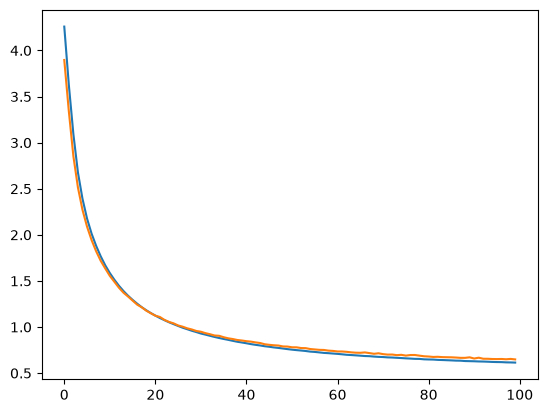

In [379]:
model2332 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2332.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2332.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2332.summary()

y_tr = le.inverse_transform(np.argmax(model2332.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2332.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6809 - loss: 1.0297 - val_accuracy: 0.7237 - val_loss: 0.7852
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7370 - loss: 0.7529 - val_accuracy: 0.7538 - val_loss: 0.7170
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7519 - loss: 0.7042 - val_accuracy: 0.7569 - val_loss: 0.6714
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7539 - loss: 0.6854 - val_accuracy: 0.7731 - val_loss: 0.6361
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7563 - loss: 0.6700 - val_accuracy: 0.7588 - val_loss: 0.6579
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7548 - loss: 0.6610 - val_accuracy: 0.7663 - val_loss: 0.6510
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7623 - loss: 0.6389 - val_accuracy: 0.7644 - val_loss: 0.6335
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7692 - loss: 0.6304 - val_accu

Model: "sequential_93"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_564 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_565 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_566 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_567 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_568 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_569 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7636
A exactitude de predición da rede neuronal no conxunto de teste é 0.7688

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.71      0.72       443
   Moderate Crash & Lethargy       0.73      0.74      0.73       509
  Severe Crash & Tachycardia       0.81      0.92      0.87       435
Sustained / Negligible Crash       0.86      0.66      0.74       213

                    accuracy                           0.77      1600
                   macro avg       0.78      0.76      0.77      1600
                weighted avg       0.77      0.77      0.77      1600

accuracity  0.7767187356948853
val_accuracy  0.768750011920929
loss  0.5829414129257202
val_loss  0.5966476202011108


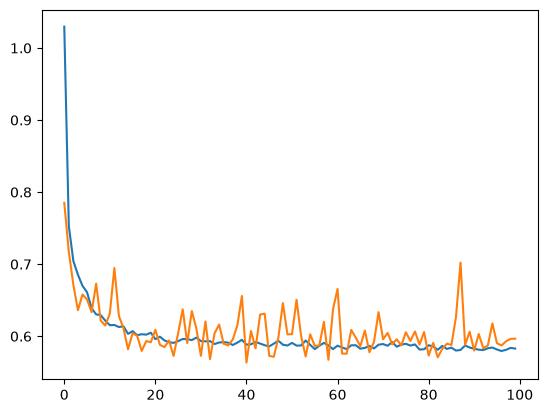

In [380]:
model2411 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2411.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2411.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2411.summary()

y_tr = le.inverse_transform(np.argmax(model2411.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2411.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7066 - loss: 1.1130 - val_accuracy: 0.7625 - val_loss: 0.7386
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7517 - loss: 0.7241 - val_accuracy: 0.7700 - val_loss: 0.6840
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7559 - loss: 0.6865 - val_accuracy: 0.7781 - val_loss: 0.6442
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7653 - loss: 0.6535 - val_accuracy: 0.7575 - val_loss: 0.6523
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7647 - loss: 0.6435 - val_accuracy: 0.7825 - val_loss: 0.6044
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7669 - loss: 0.6360 - val_accuracy: 0.7812 - val_loss: 0.5972
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7670 - loss: 0.6299 - val_accuracy: 0.7713 - val_loss: 0.6395
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7736 - loss: 0.6150 - val_accu

Model: "sequential_94"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_570 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_571 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_572 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_573 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_574 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_575 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.7989
A exactitude de predición da rede neuronal no conxunto de teste é 0.7894

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.74      0.74       443
   Moderate Crash & Lethargy       0.75      0.80      0.77       509
  Severe Crash & Tachycardia       0.90      0.84      0.87       435
Sustained / Negligible Crash       0.79      0.74      0.77       213

                    accuracy                           0.79      1600
                   macro avg       0.79      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.7837499976158142
val_accuracy  0.7893750071525574
loss  0.5575165748596191
val_loss  0.5392463803291321


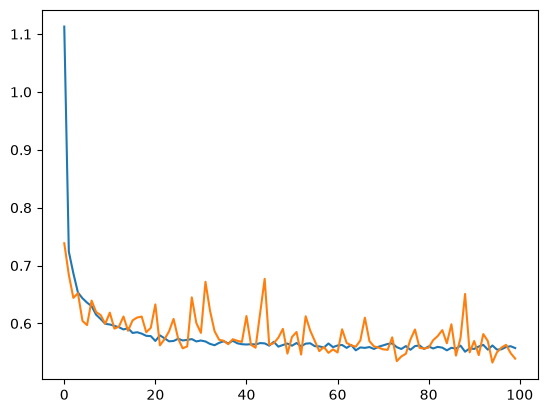

In [381]:
model2412 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2412.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.01),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2412.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2412.summary()

y_tr = le.inverse_transform(np.argmax(model2412.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2412.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6733 - loss: 2.1459 - val_accuracy: 0.7862 - val_loss: 1.2742
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7811 - loss: 1.0702 - val_accuracy: 0.7613 - val_loss: 0.9692
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7841 - loss: 0.8690 - val_accuracy: 0.7694 - val_loss: 0.8584
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7916 - loss: 0.7762 - val_accuracy: 0.7837 - val_loss: 0.7611
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7903 - loss: 0.7273 - val_accuracy: 0.7806 - val_loss: 0.7180
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7889 - loss: 0.6982 - val_accuracy: 0.7812 - val_loss: 0.6800
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7933 - loss: 0.6721 - val_accuracy: 0.7806 - val_loss: 0.6810
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7902 - loss: 0.6578 - val_accu

Model: "sequential_95"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_576 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_577 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_578 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_579 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_580 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_581 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8144
A exactitude de predición da rede neuronal no conxunto de teste é 0.7969

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.76      0.76       443
   Moderate Crash & Lethargy       0.76      0.79      0.77       509
  Severe Crash & Tachycardia       0.88      0.87      0.88       435
Sustained / Negligible Crash       0.82      0.74      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8051562309265137
val_accuracy  0.796875
loss  0.5286007523536682
val_loss  0.5510525703430176


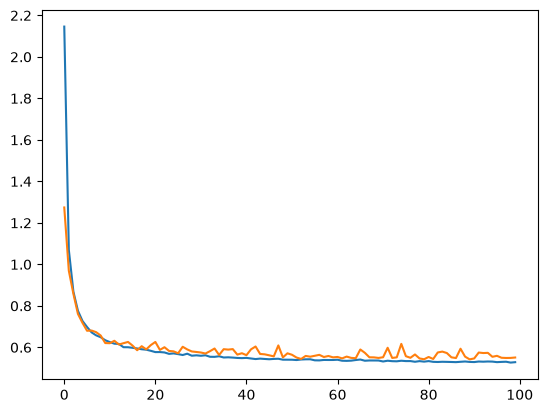

In [382]:
model2421 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2421.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2421.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2421.summary()

y_tr = le.inverse_transform(np.argmax(model2421.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2421.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6541 - loss: 2.7606 - val_accuracy: 0.7525 - val_loss: 1.8058
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7841 - loss: 1.4521 - val_accuracy: 0.7713 - val_loss: 1.2358
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7956 - loss: 1.0751 - val_accuracy: 0.7881 - val_loss: 0.9859
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7916 - loss: 0.9102 - val_accuracy: 0.7862 - val_loss: 0.8667
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7942 - loss: 0.8108 - val_accuracy: 0.7900 - val_loss: 0.7851
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7991 - loss: 0.7527 - val_accuracy: 0.7887 - val_loss: 0.7443
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7992 - loss: 0.7146 - val_accuracy: 0.7831 - val_loss: 0.7208
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7966 - loss: 0.6905 - val_accu

Model: "sequential_96"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_582 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_583 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_584 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_585 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_586 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_587 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8153
A exactitude de predición da rede neuronal no conxunto de teste é 0.8056

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.78      0.77       443
   Moderate Crash & Lethargy       0.79      0.76      0.77       509
  Severe Crash & Tachycardia       0.86      0.91      0.88       435
Sustained / Negligible Crash       0.83      0.77      0.80       213

                    accuracy                           0.81      1600
                   macro avg       0.81      0.80      0.81      1600
                weighted avg       0.81      0.81      0.80      1600

accuracity  0.8067187666893005
val_accuracy  0.8056250214576721
loss  0.524722695350647
val_loss  0.5423957705497742


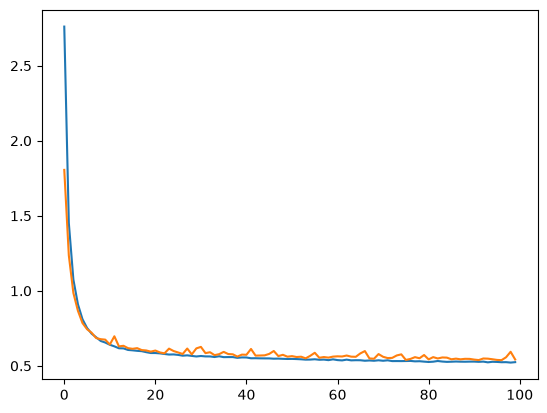

In [383]:
model2422 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2422.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2422.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2422.summary()

y_tr = le.inverse_transform(np.argmax(model2422.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2422.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.3525 - loss: 4.0978 - val_accuracy: 0.4894 - val_loss: 3.5956
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5830 - loss: 3.1685 - val_accuracy: 0.6700 - val_loss: 2.8087
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7041 - loss: 2.5280 - val_accuracy: 0.7206 - val_loss: 2.3205
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7472 - loss: 2.1403 - val_accuracy: 0.7444 - val_loss: 2.0247
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7655 - loss: 1.8878 - val_accuracy: 0.7569 - val_loss: 1.8136
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7761 - loss: 1.7080 - val_accuracy: 0.7675 - val_loss: 1.6642
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7847 - loss: 1.5720 - val_accuracy: 0.7706 - val_loss: 1.5452
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7892 - loss: 1.4673 - val_accu

Model: "sequential_97"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_588 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_589 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_590 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_591 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_592 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_593 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8223
A exactitude de predición da rede neuronal no conxunto de teste é 0.7963

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.79      0.76       443
   Moderate Crash & Lethargy       0.75      0.79      0.77       509
  Severe Crash & Tachycardia       0.90      0.85      0.87       435
Sustained / Negligible Crash       0.84      0.73      0.78       213

                    accuracy                           0.80      1600
                   macro avg       0.81      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8193749785423279
val_accuracy  0.7962499856948853
loss  0.5800922513008118
val_loss  0.6130238771438599


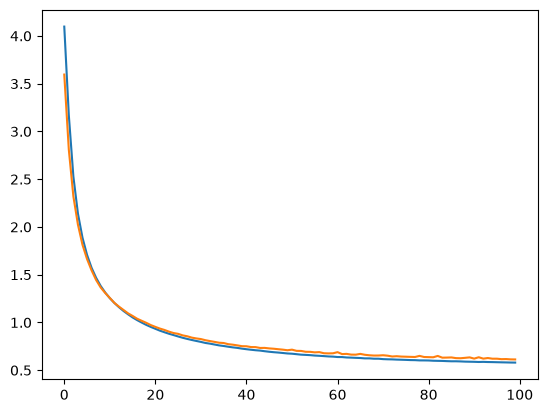

In [384]:
model2431 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2431.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.0001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2431.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2431.summary()

y_tr = le.inverse_transform(np.argmax(model2431.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2431.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3683 - loss: 4.2010 - val_accuracy: 0.4300 - val_loss: 3.8429
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5248 - loss: 3.5230 - val_accuracy: 0.5944 - val_loss: 3.2319
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6697 - loss: 2.9654 - val_accuracy: 0.6975 - val_loss: 2.7625
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7264 - loss: 2.5836 - val_accuracy: 0.7275 - val_loss: 2.4607
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7441 - loss: 2.3247 - val_accuracy: 0.7469 - val_loss: 2.2389
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7539 - loss: 2.1281 - val_accuracy: 0.7481 - val_loss: 2.0712
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7648 - loss: 1.9705 - val_accuracy: 0.7619 - val_loss: 1.9244
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7713 - loss: 1.8385 - val_accu

Model: "sequential_98"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_594 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_595 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_596 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_597 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_598 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_599 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,171 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,115 (47.33 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8203
A exactitude de predición da rede neuronal no conxunto de teste é 0.7881

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.76      0.74       443
   Moderate Crash & Lethargy       0.76      0.76      0.76       509
  Severe Crash & Tachycardia       0.91      0.83      0.87       435
Sustained / Negligible Crash       0.76      0.83      0.79       213

                    accuracy                           0.79      1600
                   macro avg       0.79      0.79      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.819531261920929
val_accuracy  0.7881249785423279
loss  0.6181315779685974
val_loss  0.6711363196372986


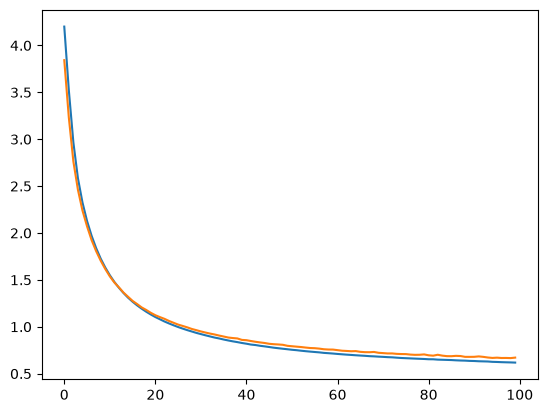

In [385]:
model2432 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2432.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    optimizer=Nadam(learning_rate=0.0001),
    # optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2432.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2432.summary()

y_tr = le.inverse_transform(np.argmax(model2432.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2432.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6611 - loss: 2.2152 - val_accuracy: 0.7588 - val_loss: 1.3607
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7822 - loss: 1.1144 - val_accuracy: 0.7756 - val_loss: 0.9830
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7867 - loss: 0.8901 - val_accuracy: 0.7812 - val_loss: 0.8283
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7825 - loss: 0.7807 - val_accuracy: 0.7756 - val_loss: 0.7675
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7862 - loss: 0.7251 - val_accuracy: 0.7738 - val_loss: 0.7324
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7866 - loss: 0.6934 - val_accuracy: 0.7694 - val_loss: 0.6993
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7919 - loss: 0.6696 - val_accuracy: 0.7937 - val_loss: 0.6492
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7942 - loss: 0.6492 - val_accu

Model: "sequential_99"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_600 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_601 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_602 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_603 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_604 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_605 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8116
A exactitude de predición da rede neuronal no conxunto de teste é 0.7906

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.77      0.76       443
   Moderate Crash & Lethargy       0.76      0.76      0.76       509
  Severe Crash & Tachycardia       0.91      0.83      0.86       435
Sustained / Negligible Crash       0.76      0.83      0.79       213

                    accuracy                           0.79      1600
                   macro avg       0.79      0.80      0.79      1600
                weighted avg       0.79      0.79      0.79      1600

accuracity  0.8034374713897705
val_accuracy  0.7906249761581421
loss  0.5199288725852966
val_loss  0.5449019074440002


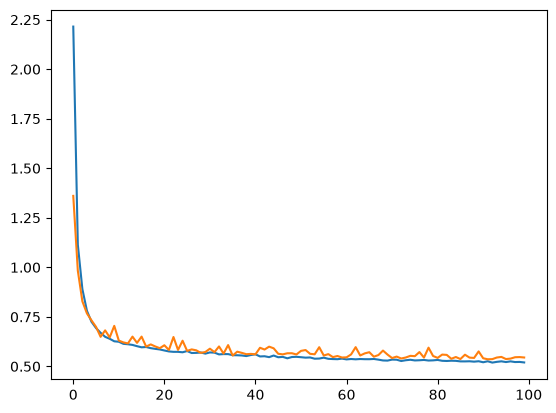

In [386]:
model2511 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2511.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2511.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2511.summary()

y_tr = le.inverse_transform(np.argmax(model2511.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2511.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6186 - loss: 2.5629 - val_accuracy: 0.7525 - val_loss: 1.5871
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7756 - loss: 1.2897 - val_accuracy: 0.7812 - val_loss: 1.1208
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7844 - loss: 1.0014 - val_accuracy: 0.7856 - val_loss: 0.9365
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8000 - loss: 0.8666 - val_accuracy: 0.7844 - val_loss: 0.8416
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7956 - loss: 0.7997 - val_accuracy: 0.7900 - val_loss: 0.7732
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7925 - loss: 0.7502 - val_accuracy: 0.7781 - val_loss: 0.7704
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7981 - loss: 0.7142 - val_accuracy: 0.8000 - val_loss: 0.6991
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7998 - loss: 0.6940 - val_accu

Model: "sequential_100"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_606 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_607 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_608 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_609 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_610 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_611 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8167
A exactitude de predición da rede neuronal no conxunto de teste é 0.7956

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.76      0.78      0.77       443
   Moderate Crash & Lethargy       0.75      0.78      0.77       509
  Severe Crash & Tachycardia       0.88      0.85      0.86       435
Sustained / Negligible Crash       0.83      0.76      0.79       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.79      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.8037499785423279
val_accuracy  0.7956249713897705
loss  0.5303462147712708
val_loss  0.5517551898956299


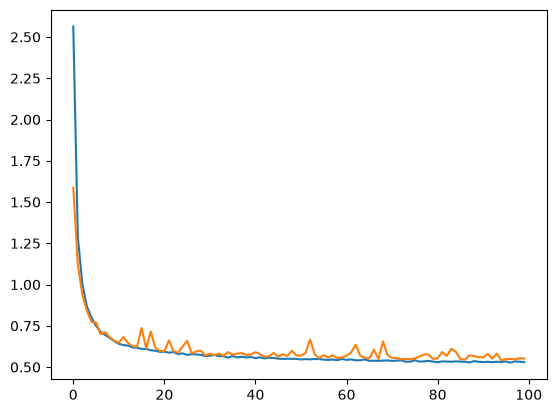

In [387]:
model2512 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2512.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2512.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2512.summary()

y_tr = le.inverse_transform(np.argmax(model2512.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2512.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6978 - loss: 1.2462 - val_accuracy: 0.7794 - val_loss: 0.7755
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7520 - loss: 0.7583 - val_accuracy: 0.7775 - val_loss: 0.6984
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7570 - loss: 0.7182 - val_accuracy: 0.7531 - val_loss: 0.7054
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7439 - loss: 0.7079 - val_accuracy: 0.7688 - val_loss: 0.6715
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7636 - loss: 0.6719 - val_accuracy: 0.7531 - val_loss: 0.6740
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7708 - loss: 0.6546 - val_accuracy: 0.7812 - val_loss: 0.6231
Epoch 7/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7703 - loss: 0.6452 - val_accuracy: 0.7706 - val_loss: 0.6536
Epoch 8/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7709 - loss: 0.6388 - val_accu

Model: "sequential_101"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_612 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_613 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_614 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_615 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_616 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_617 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8011
A exactitude de predición da rede neuronal no conxunto de teste é 0.7994

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.75      0.77      0.76       443
   Moderate Crash & Lethargy       0.78      0.76      0.77       509
  Severe Crash & Tachycardia       0.88      0.88      0.88       435
Sustained / Negligible Crash       0.80      0.79      0.80       213

                    accuracy                           0.80      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.80      0.80      0.80      1600

accuracity  0.7925000190734863
val_accuracy  0.7993749976158142
loss  0.5404186844825745
val_loss  0.5261777639389038


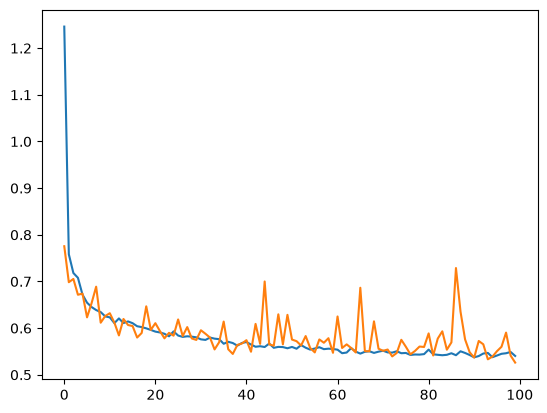

In [388]:
model2521 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2521.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.004, weight_decay=0.0002),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2521.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=8, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2521.summary()

y_tr = le.inverse_transform(np.argmax(model2521.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2521.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])

Epoch 1/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6842 - loss: 1.3785 - val_accuracy: 0.7381 - val_loss: 0.8455
Epoch 2/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7598 - loss: 0.7672 - val_accuracy: 0.7219 - val_loss: 0.7985
Epoch 3/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7611 - loss: 0.7119 - val_accuracy: 0.7456 - val_loss: 0.7532
Epoch 4/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7688 - loss: 0.6861 - val_accuracy: 0.7812 - val_loss: 0.6388
Epoch 5/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7681 - loss: 0.6706 - val_accuracy: 0.7806 - val_loss: 0.6430
Epoch 6/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7763 - loss: 0.6528 - val_accuracy: 0.7550 - val_loss: 0.7164
Epoch 7/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7825 - loss: 0.6291 - val_accuracy: 0.7713 - val_loss: 0.6394
Epoch 8/100
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7798 - loss: 0.6321 - val_accu

Model: "sequential_102"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_618 (Dense)               │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_619 (Dense)               │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_620 (Dense)               │ (None, 60)             │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_621 (Dense)               │ (None, 20)             │         1,220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_622 (Dense)               │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_623 (Dense)               │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,170 (70.98 KB)

 Trainable params: 6,056 (23.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,114 (47.32 KB)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8075
A exactitude de predición da rede neuronal no conxunto de teste é 0.7944

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.79      0.76       443
   Moderate Crash & Lethargy       0.78      0.73      0.75       509
  Severe Crash & Tachycardia       0.88      0.87      0.87       435
Sustained / Negligible Crash       0.79      0.81      0.80       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.80      0.79      0.79      1600

accuracity  0.7890625
val_accuracy  0.7943750023841858
loss  0.5341857075691223
val_loss  0.5315251350402832


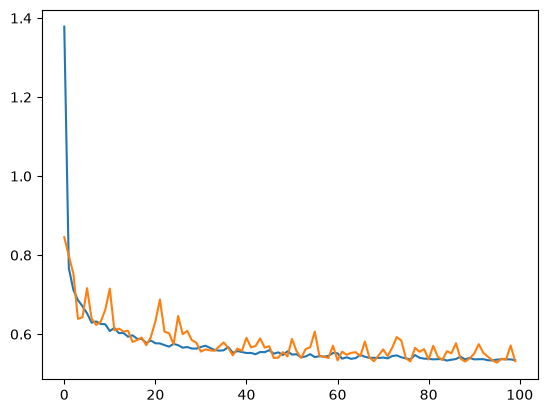

In [389]:
model2522 = Sequential([
    layers.Input(shape=(x2_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(60, activation='softplus', kernel_initializer='glorot_uniform', kernel_regularizer= L2(0.01)),
    layers.Dense(20, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
    layers.Dense(4, activation='softmax')
])

model2522.compile(
    # optimizer=SGD(learning_rate=0.0001, nesterov=True),
    # optimizer=Adam(learning_rate=0.0001),
    # optimizer=Nadam(learning_rate=0.0001),
    optimizer=AdamW(learning_rate=0.004, weight_decay=0.0002),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cerebro = model2522.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=100,
    batch_size=16, # modificar isto a 2^n
    # validation_split=0.2 
    validation_data = (x2_test_scaled,y2_test_enc)
)

model2522.summary()

y_tr = le.inverse_transform(np.argmax(model2522.predict(x2_train_scaled), axis=1))
y_te = le.inverse_transform(np.argmax(model2522.predict(x2_test_scaled), axis=1))

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y_tr):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y_te):.4f}\n')

print(
    classification_report(
        y2_test,
        y_te,
        target_names=labels_1
    )
)

plt.plot(cerebro.history['loss'])
plt.plot(cerebro.history['val_loss'])
print('accuracity ',cerebro.history['accuracy'][-1])
print('val_accuracy ',cerebro.history['val_accuracy'][-1])
print('loss ',cerebro.history['loss'][-1])
print('val_loss ',cerebro.history['val_loss'][-1])